# zf1 — Measure

`metadata.hera.policy` — scientific record: append new cells; never edit or
delete executed ones. (Who *executes* a measure cell is set by the session
mode — see the brief.)

Confirm each `# <-- verify` (rig: addresses) and `# <-- validate` (device:
operating limits, wiring) line at bring-up. Cells marked **PATTERN** /
**PROPOSAL** carry `<PLACEHOLDER>` values — review before running.

## Setup

In [1]:
import os
import time

import numpy as np
import scipy.constants as cst
from tqdm.notebook import tqdm

import qcodes
from qcodes import validators
from qcodes.instrument_drivers.stanford_research import SR830, SR860
from qcodes.instrument_drivers.Keithley import Keithley2400
from qcodes.instrument_drivers.american_magnetics import AMIModel430

import sweep

from hera.analysis import GateCalibration, field_invB

from sharpelab_nb.constants import TOPLOADER
from sharpelab_nb.thermometry import temperature_from_logfiles
from sharpelab_nb.drivers import SRS_DC205

In [2]:
main_dir = os.getcwd()
sweep.set_basedir(os.path.join(main_dir, "data"))
main_dir

'C:\\Users\\toploader\\measurements\\aaron\\20260625-zf1'

# Connect Instruments

## Magnet

In [3]:
MAGNET_ADDR = "TCPIP0::192.168.0.101::7180::SOCKET"  # <-- verify address
magnet = AMIModel430("magnet", address=MAGNET_ADDR)
# Field in Tesla; magnet.field() is the MEASURED readback (coil constant
# 0.116783 T/A is configured on the unit). magnet.field(target) BLOCKS until
# the supply reports holding; a kernel interrupt does NOT stop the ramp.
magnet.field()

Connected to: AMERICAN MAGNETICS INC. 430 (serial:430-11-044, firmware:2.65) in 0.87s


-1.5455e-05

## Thermometry (file-based) + sample heater

Kernel temperature reads are **file-based**, not GPIB — the AVS bridge workers
own the bridges and write the logfiles. `temperature` is the loaded probe's
mixing chamber; the logfile path is **probe-dependent** (Probe1 = straight,
Probe2 = rotator). The sample heater is an **open-loop** Keithley voltage
source — set `heater.volt`, settle, then read T back from `temperature()`.

In [4]:
# Probe MC (sample T) — auto-picks the live probe logfile (Probe1 straight / Probe2 rotator), warns >300 s stale
temperature = temperature_from_logfiles(
    "T", TOPLOADER.temp_logfile_candidates["T_probe"])  # <-- verify loaded probe is the live one
fridge_temperature = temperature_from_logfiles("T_fridge", TOPLOADER.temp_logfile_candidates["T_fridge"])
mag_temperature = temperature_from_logfiles("T_magnet", TOPLOADER.temp_logfile_candidates["T_magnet"])
print("probe MC:", temperature(), "K")

# Sample-stage heater — open-loop voltage drive (V->T is per-cooldown; device card)
heater = Keithley2400("heater", "GPIB4::12::INSTR")  # <-- verify address
heater.mode.set("VOLT")
heater.volt.step = 0.005

probe MC: 0.03382 K
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:1299232, firmware:C30   Mar 17 2006 09:29:29/A02  /K/J) in 0.12s


## Lock-ins

In [5]:
sr830_1 = SR830("sr830_1", "GPIB0::8::INSTR")  # <-- verify — current channel (Ithaco 1211 preamp output)
sr830_2 = SR830("sr830_2", "GPIB0::9::INSTR")  # <-- verify
sr830_3 = SR830("sr830_3", "GPIB0::4::INSTR")  # <-- verify
sr830_4 = SR830("sr830_4", "GPIB0::1::INSTR")  # <-- verify
sr830_5 = SR830("sr830_5", "GPIB0::5::INSTR")  # <-- verify
sr830_6 = SR830("sr830_6", "GPIB0::6::INSTR")  # <-- verify
sr830_7 = SR830("sr830_7", "GPIB0::7::INSTR")  # <-- verify
# sr830_8 = SR860("sr830_8", "TCPIP::192.168.0.107::inst0::INSTR")  # <-- verify — SR860; enable if used

C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_1 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_2 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n45469, firmware:ver1.07) in 0.14s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45595, firmware:ver1.07) in 0.11s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45471, firmware:ver1.07) in 0.10s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_3 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_4 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages

Connected to: Stanford_Research_Systems SR830 (serial:s/n43722, firmware:ver1.07) in 0.20s
Connected to: Stanford_Research_Systems SR830 (serial:s/n45470, firmware:ver1.07) in 0.09s
Connected to: Stanford_Research_Systems SR830 (serial:s/n43721, firmware:ver1.07) in 0.10s
Connected to: Stanford_Research_Systems SR830 (serial:s/n41621, firmware:ver1.07) in 0.11s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_6 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch1_databuffer on instrument sr830_7 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(
C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\instrument\instrument_base.py:188: QCoDeSDeprecationWarning: Parameter ch2_databuffer on instrument sr830_7 does not correctly pass kwargs to its baseclass. A Parameter class must take `**kwargs` and forward them to its baseclass.
  warnings.warn(


## Keithleys (gates)

In [6]:
# Gate Keithleys are role-named on this rig (k_tg/k_bg drive top/back gates),
# so recipes' k_tg / k_bg resolve directly. The third Keithley's role is
# per-insert (Si gate, or a probe-specific winding). Defaults: rangev 21,
# rangei 1uA, compliance 10 nA / 20 V, step 5 mV.
def _setup_k2400(k):
    # k.mode.set("VOLT")
    # k.rangev.set(21)
    # k.rangei.set(1e-6)
    # k.compliancev.set(20)
    # k.compliancei.set(1e-8)
    k.volt.step = 0.005
    return k

k_tg  = _setup_k2400(Keithley2400("k_tg",  "GPIB4::9::INSTR"))   # <-- verify — top gate
k_bg  = _setup_k2400(Keithley2400("k_bg",  "GPIB4::10::INSTR"))  # <-- verify — back gate
k_tg2 = _setup_k2400(Keithley2400("k_tg2", "GPIB4::11::INSTR"))  # <-- verify — third Keithley (per-insert role)

Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028439, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.04s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028442, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s
Connected to: KEITHLEY INSTRUMENTS INC. 2400 (serial:4028489, firmware:C32   Oct  4 2010 14:20:11/A02  /T/K) in 0.03s


## DC205 (DC current bias)

On the toploader, gates are Keithleys; the DC205s are **DC current-bias**
sources (through a 100 MΩ series resistor — see the device card). Set
`volt -> 0` before reconfiguring or ending a measurement.

In [7]:
dc205_1 = SRS_DC205("dc205_1", "ASRL6::INSTR")  # <-- verify address — DC current bias
dc205_1.volt = dc205_1.voltage
dc205_1.volt.step = 0.005

dc205_3 = SRS_DC205("dc205_3", "ASRL7::INSTR")  # <-- verify address — second DC205
dc205_3.volt = dc205_3.voltage
dc205_3.volt.step = 0.005

Connected to: Stanford_Research_Systems DC205 (serial:s/n20500516, firmware:ver1.80) in 0.02s
Connected to: Stanford_Research_Systems DC205 (serial:s/n20500513, firmware:ver1.80) in 0.03s


# SAFETIES

Run immediately after instrument bring-up, before any sweep.

In [8]:
# slot: gate-validators — operating limits from the device card's gate-
# operating-limits table; commit EXACTLY the card numbers. Each value
# `# <-- validate`.
TG_MIN, TG_MAX = -7.0, +6.0   # top gate (k_tg), V    # <-- validate
BG_MIN, BG_MAX = -4.0, +4.2   # back gate (k_bg), V    # <-- validate
k_tg.volt.vals = validators.Numbers(TG_MIN, TG_MAX)
k_bg.volt.vals = validators.Numbers(BG_MIN, BG_MAX)

# Limit lists for sanitize_tg_bg()
tg_lims, bg_lims = [TG_MIN, TG_MAX], [BG_MIN, BG_MAX]

# Session field cap — machine-enforced: magnet.field is a qcodes Parameter, so
# this validator rejects magnet.field(target) with |B| > cap before any
# hardware traffic. Driver backstop: |B| <= COIL? x current_limit (~9 T) on the
# AMI430 unit.
B_SESSION_CAP = 0.1  # Tesla = 100 mT    # <-- validate (session cap from brief: |B| <= 100 mT, committed)
magnet.field.vals = validators.Numbers(-B_SESSION_CAP, B_SESSION_CAP)

# Sample-heater ceiling for sustained runs (V, not T — open-loop drive).
HEATER_V_MAX = 6.5  # V    # <-- validate
heater.volt.vals = validators.Numbers(0, HEATER_V_MAX)

# DC current-bias range (SRS DC205 hardware: +/-15 V -> +/-150 nA at 100 MOhm).
dc205_1.volt.vals = validators.Numbers(-15, 15)

# Helpers

In [9]:
def spoints(a, b, c):
    return np.linspace(a, b, c)


def sanitize_tg_bg(vtg_vec, vbg_vec, tg_lims, bg_lims):
    """
    Given a list of tg and bg voltages, removes any points which are outside tg_lims and bg_lims
    """
    vtg_new_vec = []
    vbg_new_vec = []
    for ind in range(len(vtg_vec)):
        vtg, vbg = vtg_vec[ind], vbg_vec[ind]
        if vtg < tg_lims[0] or vtg > tg_lims[1] or vbg < bg_lims[0] or vbg > bg_lims[1]:
            pass
        else:
            vtg_new_vec.append(vtg)
            vbg_new_vec.append(vbg)
    return np.array(vtg_new_vec), np.array(vbg_new_vec)


def interruptable_sleep(total: float, chunk: float = 0.1):
    """
    Sleep for `total` seconds in chunks of `chunk` seconds, breakable by a
    kernel interrupt and showing a tqdm progress bar rounded to 0.1 s. Use
    this for any wait longer than a few seconds (thermalization, base-T
    recovery, magnet settle) so the operator's interrupt lands cleanly.
    """
    bar_fmt = "{l_bar}{bar}| {n:.1f}/{total:.1f}s [{postfix}]"
    with tqdm(total=total, desc="Sleeping", unit="s", bar_format=bar_fmt) as pbar:
        end = time.monotonic() + total
        while True:
            remaining = max(0.0, end - time.monotonic())
            if remaining <= 0:
                pbar.update(round(pbar.total - pbar.n, 1))
                pbar.set_postfix_str("0.0s left")
                break
            step = min(chunk, remaining)
            time.sleep(step)
            pbar.update(round(step, 1))
            pbar.n = round(pbar.n, 1)
            pbar.set_postfix_str(f"{round(end - time.monotonic(), 1):.1f}s left")
            pbar.refresh()

In [10]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

# Measurement config

In [11]:
# slot: meas-config — channel/contact assignments + gains from the device
# card's Measurement setup (current channel + gain, provided contact
# configuration). Each value `# <-- validate`. Toploader contacts are wired
# DIRECT (no QSwitch) — name the contact pair per channel. Always set 'comment'
# per run — structured, current, no inherited text.
meas_config = {
    "sr1": "5-4",     "sr1_gain": -1e6,   # current channel (Ithaco 1211)    # <-- validate
    "sr2": "5-4",     "sr2_gain": 1e2,    # 2T voltage (x100 preamp)    # <-- validate
    "sr3": "30-31",   "sr3_gain": 1e2,    # 4T longitudinal Rxx (x100 preamp)    # <-- validate
    "bias_resistor": 1e8,
    "bias_channel": "sr830_1",   # drive lock-in; I_bias = its live amplitude / bias_resistor (amp+freq auto-snapshotted)    # <-- validate
    "comment": "<SET PER RUN>",
}


# HERA — session start (2026-06-25)

## HERA — Gate C: re-entry baseline (constant-D n-cut, D = −0.64)

Bring-up passed: instruments connected & reading (magnet −0.015 mT, probe MC 33.8 mK, all lock-ins/gates/DC205 alive); SAFETIES committed in-kernel = device-card limits (TG −7/+6, BG −4/+4.2) + |B|≤100 mT + heater ≤6.5 V; probe (Probe2/rotator) logfile fresh to ~13 s, fridge logs advancing — **not** the stale-logfile trap. (n,D) calibration roundtrips the optimum exactly (n=−5.0, D=−0.64 → V_tg=−5.365, V_bg=+3.987).

**This cell** is the re-entry check before the campaign: a fast n-linecut at fixed **D=−0.64** (the provisional widest-point), n from −4.0→−6.0×10¹¹ (0.05 step, 41 pts), AC 1 nA, 4T sens 1 mV. Expect Rxx(4T, 30-31)→~0 near n≈−5.0×10¹¹ with normal/metallic flanks both sides — i.e. the dome survived handover. Coverage: this brackets the dome core into normal on both sides but is **1D** (Fig 1 does the 2D zoom next); it does not probe the high-|D| flank.

**Preconditions printed at top — eyeball before trusting the run:** T<60 mK, |B|<5 mT, heater=0, and gates reported (expected ~at the dome from the prior handoff). Cell asserts on T/B/heater.

**~1–1.5 min** (41 pts × ~1.2 s + a few-second gate ramp from the dome). Ends by parking gates **at the optimum** (V_tg=−5.365, V_bg=+3.987) so we're positioned for Step 0 (B_eff0). I'll read the result from disk and compare to runs 5–8 before proposing Step 0.


T = 33.8 mK        (expect ~34 base)
B = -0.0108 mT       (expect ~0)
V_tg = -5.365 V        (expect ~-5.365, held at dome from handoff)
V_bg = 3.987 V        (expect ~+3.987, held at dome from handoff)
heater = 0.000 V          (expect 0)
cut: 41 pts; V_tg in [-5.436,-5.294], V_bg in [3.927,4.047]
2026-06-25 12:39:48,524 [INFO] Ramping k_tg_volt: -5.365 -> -5.293598300008078
2026-06-25 12:39:48,676 [INFO] Ramping k_bg_volt: 3.987 -> 4.047233079089199


Sleeping:   0%|          | 0.0/10.0s []

2026-06-25 12:39:58,797 [INFO] Starting multisweep with ID 0
2026-06-25 12:39:58,798 [INFO] Minimum duration 0h 0m 49s


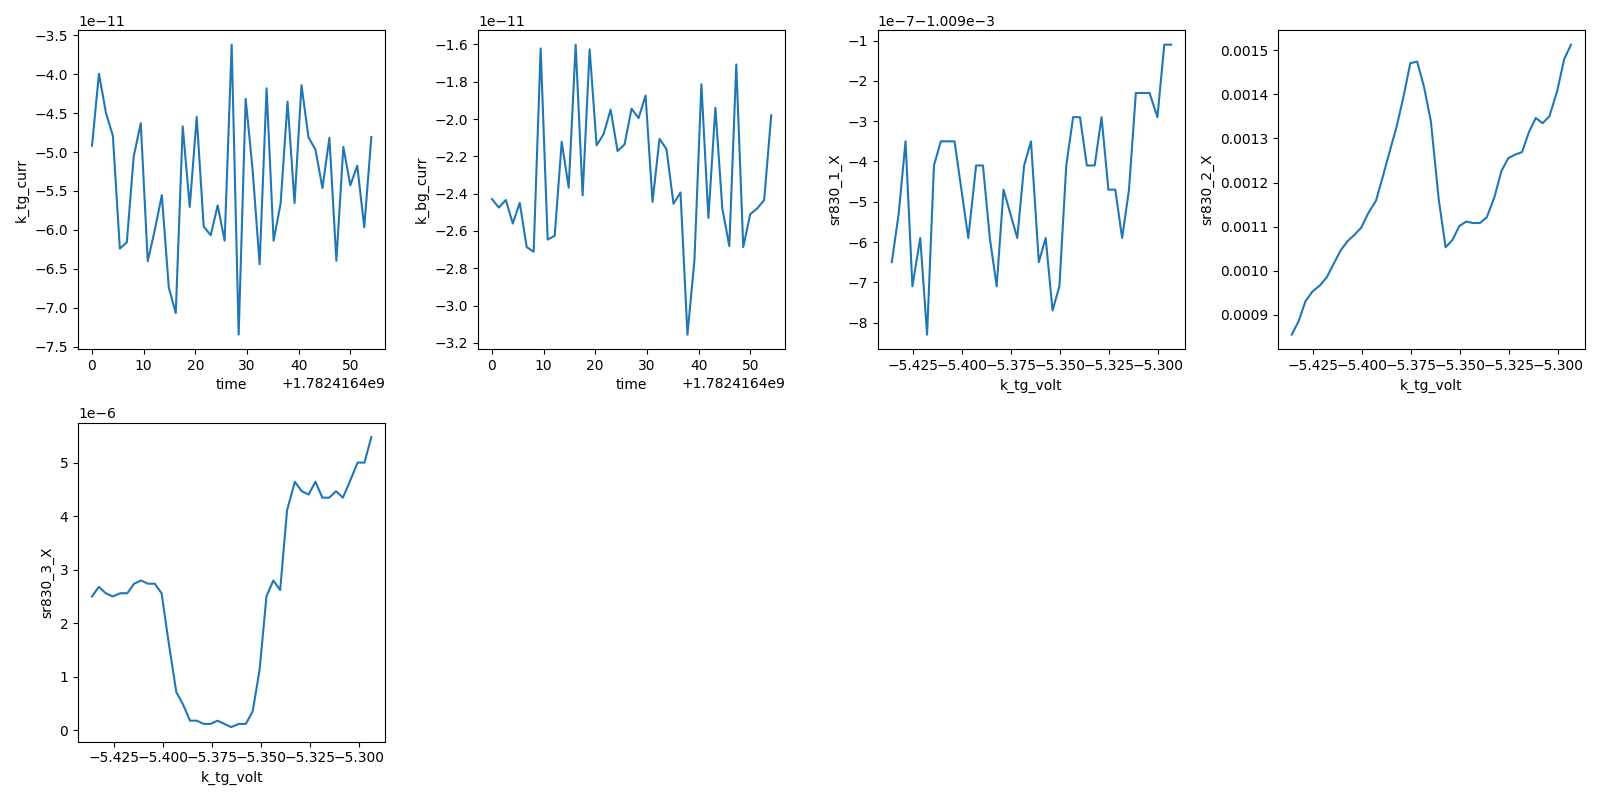

2026-06-25 12:40:54,922 [INFO] Completed in 0h 0m 55s
2026-06-25 12:40:54,923 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\0\data.tsv.gz
2026-06-25 12:40:54,992 [INFO] Ramping k_tg_volt: -5.436 -> -5.36477247080011
2026-06-25 12:40:55,148 [INFO] Ramping k_bg_volt: 3.9265 -> 3.986915985197646
done; gates parked at optimum n=-5.0e11, D=-0.64 (V_tg=-5.365, V_bg=+3.987)


In [12]:
# === Gate-C re-entry baseline — constant-D n-linecut at D = -0.64 V/nm ===
# Reproduce the SC dome arc on this fresh kernel/session before committing
# to the high-res campaign. Expect Rxx(4T, 30-31) -> ~0 near n = -5.0e11,
# normal/metallic on both flanks. Compare to prior runs 5-8 (20260624-4-zf1).
import scipy.constants as cst

# --- silent-precondition reads (expected vs actual; STOP on mismatch) ---
T_now = temperature(); B_now = magnet.field()
Vtg_now = k_tg.volt(); Vbg_now = k_bg.volt(); Hv = heater.volt()
print(f"T = {T_now*1e3:.1f} mK        (expect ~34 base)")
print(f"B = {B_now*1e3:.4f} mT       (expect ~0)")
print(f"V_tg = {Vtg_now:.3f} V        (expect ~-5.365, held at dome from handoff)")
print(f"V_bg = {Vbg_now:.3f} V        (expect ~+3.987, held at dome from handoff)")
print(f"heater = {Hv:.3f} V          (expect 0)")
assert T_now < 0.060, f"T high: {T_now*1e3:.1f} mK"
assert abs(B_now) < 0.005, f"B off-zero: {B_now*1e3:.3f} mT"
assert Hv < 0.01, f"heater on: {Hv:.3f} V"

# --- (n,D) calibration: USE EXACTLY (handoff §1; ratio data-pinned, n_off from CNP) ---
N_OFF = -0.362e11 * 1e4   # m^-2
cal_r4 = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2, n_offset=N_OFF)
c_tg, c_bg = cal_r4.c_tg, cal_r4.c_bg
e, eps0 = cst.e, cst.epsilon_0
def nD_to_V(n_cm2, D_Vnm):
    n = np.asarray(n_cm2)*1e4; D = np.asarray(D_Vnm)*1e9
    A = (n - cal_r4.n_offset)*e; B = (D - cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg), (A-B)/(2*c_bg)

# --- AC sense config: 1 nA drive; 4T (sr830_3) at 1 mV for low-R SC region ---
dc205_1.volt(0.0)            # zero DC bias for AC sense
sr830_1.amplitude(0.1)       # 0.1 V -> 1 nA through 100 MOhm
sr830_2.sensitivity(0.005)   # 2T (5-4): 50 kOhm ceiling
sr830_3.sensitivity(0.001)   # 4T (30-31): resolves tens of Ohm; SC channel
k_tg.nplci(1); k_bg.nplci(1)

# --- D = -0.64 cut, n -4.0 -> -6.0e11 (0.05 step, 41 pts): brackets dome into normal both flanks ---
D0 = -0.64
n_scan = np.arange(-4.0, -6.01, -0.05) * 1e11
vtg, vbg = nD_to_V(n_scan, D0)
vtg, vbg = sanitize_tg_bg(vtg, vbg, tg_lims, bg_lims)
print(f"cut: {len(vtg)} pts; V_tg in [{vtg.min():.3f},{vtg.max():.3f}], V_bg in [{vbg.min():.3f},{vbg.max():.3f}]")

meas_config["comment"] = (f"re-entry baseline; constant-D n-cut D={D0:+.2f} V/nm; "
                          f"n -4.0->-6.0e11 (0.05 step), {len(vtg)} pts; AC 1 nA; 4T sens 1 mV; B~0, base T")
s = sweep.AsyncStation(meas_config)
s.add_comment('re-entry-baseline')
s.add_comment('constant-D n-linecut (gate-C re-entry); reproduce SC dome arc vs prior runs 5-8')
s.add_comment(meas_config["comment"])
s.ramp(k_tg.volt, vtg[0]); s.ramp(k_bg.volt, vbg[0]); interruptable_sleep(10)
xp = k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(temperature)
for lia in (sr830_1, sr830_2, sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr)   # TG leakage
s.plot('time', k_bg.curr)   # BG leakage
s.plot(xp, sr830_1.X)       # current monitor
s.plot(xp, sr830_2.X)       # 2T (5-4)
s.plot(xp, sr830_3.X)       # 4T Rxx (30-31) -- the SC channel
try:
    s.multisweep([k_tg.volt, k_bg.volt], [vtg, vbg], delay=1.2)
finally:
    # leave gates at the dome optimum (n=-5.0, D=-0.64) -> positioned for Step 0
    vt_opt, vb_opt = nD_to_V(-5.0e11, D0)
    s.ramp(k_tg.volt, float(vt_opt)); s.ramp(k_bg.volt, float(vb_opt))
print("done; gates parked at optimum n=-5.0e11, D=-0.64 (V_tg=-5.365, V_bg=+3.987)")


## HERA — Step 0: effective-zero field B_eff0 (do ONCE)

Run 0 confirmed the dome: Rxx = 0.60 Ω at n=−5.00×10¹¹, D=−0.64 (the prior optimum, mV-exact), <75 pA leakage, 34 mK. Gates are parked there now.

**This cell** locates the cooldown's trapped-flux-compensated **B=0** at the optimum — needed because B_c⊥≈1.8 mT means nominal-0 isn't paper-grade. Rxx vs B⊥ as **two one-sided cuts** (+5→0 and −5→0, 0.1 mT step, ~4 s/pt, AC 1 nA, DC bias 0). Each half is swept **monotonically toward 0** — field-discipline-compliant; the ramps to ±5 mT are positioning, not measurement. I take B_eff0 = the fitted symmetric-dip center; ±0.1–0.2 mT is plenty (flat bottom). This is **one-time** — trapped flux is fixed at these scales, so no re-locating after Fig 4 / Fraunhofer.

**Note (field discipline):** I'm *not* using a cross-zero −5→+5 pass here — that's authorized only for Fig 2 (Fraunhofer). The two-halves route carries a small inter-half remanence mismatch (it gave the +1.4/−2.15 mT asymmetry in prior runs 11/12), but that's well inside the flat dip bottom and below the precision B_eff0 needs. If you'd rather take a single cross-zero pass for a cleaner center, say so and I'll re-cast it.

**Preconditions (printed/asserted at top):** T<60 mK, |B|<5 mT at start, gates within 10 mV of the optimum, heater=0. **~8–9 min** total (2×51 pts × ~4 s + two positioning ramps/settles). Two data files (the two halves). Ends with magnet at 0, gates at the optimum. I'll fit both halves for B_eff0 and report before Fig 1.


T = 33.7 mK     (expect ~34)
B = -0.0117 mT    (expect ~0)
V_tg = -5.365 V     (expect -5.365, optimum)
V_bg = 3.987 V     (expect +3.987, optimum)
heater = 0.000 V       (expect 0)
magnet ramp_rate = 1.000 mT/s
2026-06-25 12:45:33,888 [INFO] Ramping magnet_field: -9.715e-06 -> 0.005


Sleeping:   0%|          | 0.0/20.0s []

positioned at B = 5.001 mT; sweeping +5 -> 0
2026-06-25 12:46:08,377 [INFO] Starting sweep with ID 1
2026-06-25 12:46:08,378 [INFO] Minimum duration 0h 3m 24s


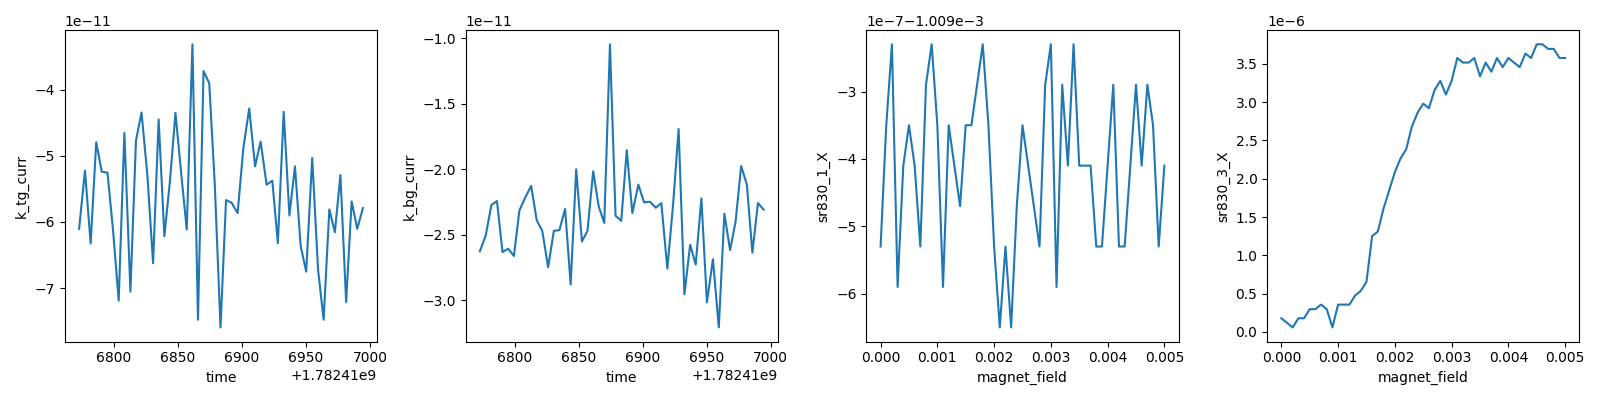

2026-06-25 12:49:55,300 [INFO] Completed in 0h 3m 46s
2026-06-25 12:49:55,301 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\1\data.tsv.gz
2026-06-25 12:49:55,361 [INFO] Ramping magnet_field: 8.831e-06 -> -0.005


Sleeping:   0%|          | 0.0/20.0s []

positioned at B = -5.003 mT; sweeping -5 -> 0
2026-06-25 12:50:29,369 [INFO] Starting sweep with ID 2
2026-06-25 12:50:29,370 [INFO] Minimum duration 0h 3m 24s


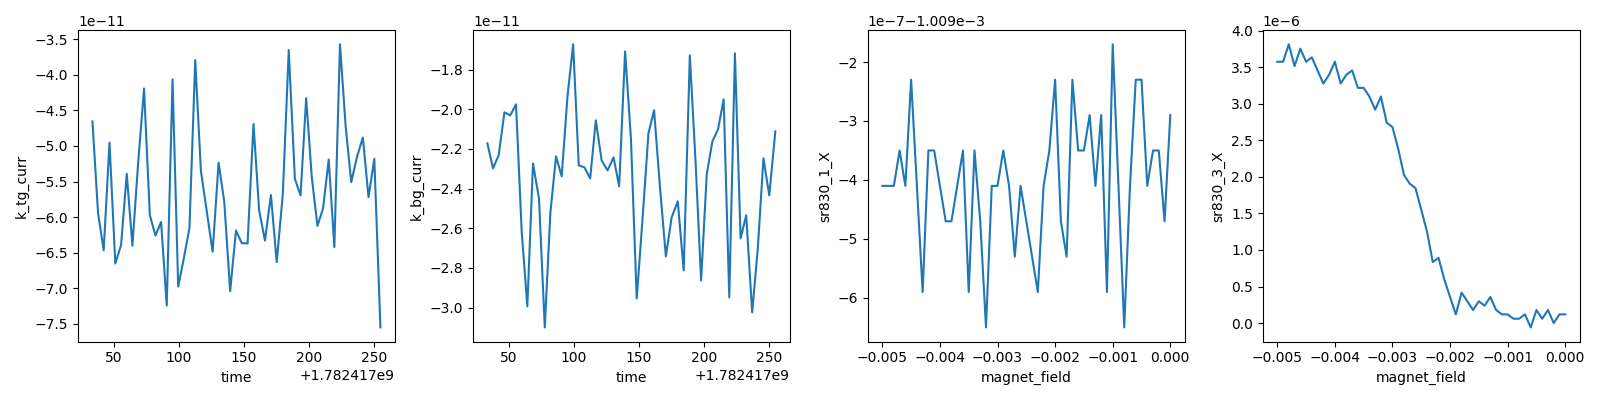

2026-06-25 12:54:15,654 [INFO] Completed in 0h 3m 45s
2026-06-25 12:54:15,655 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\2\data.tsv.gz
2026-06-25 12:54:15,745 [INFO] Ramping magnet_field: -2.3403e-05 -> 0.0
done; magnet at -0.018 mT, gates held at optimum


In [13]:
# === Step 0 — effective-zero (B_eff0) calibration (ONCE, at the optimum) ===
# Rxx vs B_perp around 0 to find the symmetric-dip center = the cooldown's
# trapped-flux-compensated "B=0". Discipline-compliant: TWO one-sided cuts,
# each swept TOWARD 0 (+5->0 and -5->0); positioning ramps are not measurements.
# Gates held at the optimum (n=-5.0e11, D=-0.64). Zero DC bias, AC sense.

# --- silent-precondition reads ---
T_now = temperature(); B_now = magnet.field()
Vtg_now = k_tg.volt(); Vbg_now = k_bg.volt(); Hv = heater.volt()
print(f"T = {T_now*1e3:.1f} mK     (expect ~34)")
print(f"B = {B_now*1e3:.4f} mT    (expect ~0)")
print(f"V_tg = {Vtg_now:.3f} V     (expect -5.365, optimum)")
print(f"V_bg = {Vbg_now:.3f} V     (expect +3.987, optimum)")
print(f"heater = {Hv:.3f} V       (expect 0)")
assert T_now < 0.060, f"T high: {T_now*1e3:.1f} mK"
assert abs(B_now) < 0.005, f"B off-zero at start: {B_now*1e3:.3f} mT"
assert abs(Vtg_now - (-5.365)) < 0.010, f"V_tg off optimum: {Vtg_now:.3f}"
assert abs(Vbg_now - (+3.987)) < 0.010, f"V_bg off optimum: {Vbg_now:.3f}"
assert Hv < 0.01, f"heater on: {Hv:.3f} V"

# --- AC sense config: 1 nA, 4T sens 1 mV, zero DC bias ---
dc205_1.volt(0.0)
sr830_1.amplitude(0.1)        # 1 nA
sr830_2.sensitivity(0.005)
sr830_3.sensitivity(0.001)    # 4T (30-31), SC channel
print(f"magnet ramp_rate = {magnet.ramp_rate()*1e3:.3f} mT/s")

B_AMP = 5e-3       # +/-5 mT span
B_STEP = 0.1e-3    # 0.1 mT
NPTS = int(round(2*B_AMP/B_STEP/2)) + 1   # 51 pts per one-sided half (5->0)
DLY = 4.0          # ~4 s dwell/pt so each 0.1 mT step thermalizes

meas_config["comment"] = ("Step0 B_eff0 calibration at optimum (n=-5.0e11, D=-0.64); "
                          "Rxx vs B_perp; two one-sided cuts +5->0 and -5->0; "
                          "0.1 mT step, ~4 s/pt; AC 1 nA, 4T sens 1 mV, DC bias 0")
s = sweep.AsyncStation(meas_config)
s.add_comment('field-sweep-1d')
s.add_comment('Step 0: effective-zero (B_eff0) calibration, one-sided pair toward 0')
s.add_comment(meas_config["comment"])
xp = magnet.field
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr); s.fp(temperature)
for lia in (sr830_1, sr830_2, sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)
s.plot(xp, sr830_1.X)       # current monitor
s.plot(xp, sr830_3.X)       # 4T Rxx vs B -- the field-kill dip

try:
    # --- half A: +5 -> 0 mT (one-sided toward 0) ---
    s.add_comment('half A: +5 -> 0 mT')
    s.ramp(magnet.field, +B_AMP); interruptable_sleep(20)   # position + settle
    print(f"positioned at B = {magnet.field()*1e3:.3f} mT; sweeping +5 -> 0")
    s.sweep(magnet.field, np.linspace(+B_AMP, 0.0, NPTS), delay=DLY)

    # --- half B: -5 -> 0 mT (one-sided toward 0) ---
    s.add_comment('half B: -5 -> 0 mT')
    s.ramp(magnet.field, -B_AMP); interruptable_sleep(20)   # position + settle
    print(f"positioned at B = {magnet.field()*1e3:.3f} mT; sweeping -5 -> 0")
    s.sweep(magnet.field, np.linspace(-B_AMP, 0.0, NPTS), delay=DLY)
finally:
    s.ramp(magnet.field, 0.0)
print(f"done; magnet at {magnet.field()*1e3:.3f} mT, gates held at optimum")


## HERA — Figure 1: high-res (n,D) dome zoom (nD-map) at B = B_eff0

Step 0 done: **B_eff0 = −0.366 mT** (ana cell executed). This cell takes the headline dome map at that true zero field.

**Grid:** n ∈ [−6.0, −4.3]×10¹¹ **fast (0.02 step, 86 pts)** × D ∈ [−0.66, −0.56] **slow (0.005 step, 21 rows)** = **1806 pts**, boustrophedon, AC 1 nA, 4T sens 1 mV, DC bias 0. ~2.5× finer than run 8 (0.05×0.01). All points verified inside validators — **no clipping** (rectangular grid). Field held at B_eff0 throughout (`fp`'d for the record).

**Coverage trade (on the page):** the high-|D| edge D=−0.66 rides near the BG +4.2 V cap (max V_bg = 4.163 V) — this is the known validator-limited flank; the dome may continue just beyond reach there. I cap D at −0.66 to stay safe; going further needs the BG validator raised (consent-gated, not proposed). The fast axis brackets the dome core into normal both sides.

**Purpose:** select the **widest-point D-line** (provisionally −0.64) and the **optimal n** (Rxx-min on that line) that Figs 3/4/5 and the Fraunhofer all ride.

**~65–70 min** (1806 pts × ~2.1 s/pt at delay 2 + ramps; priced off run 0's 1.34 s/pt at delay 1.2, +session margin). **Checkpoints** (I'll watch live): **(1) first D-row (~86 pts, ~3 min)** — leakage <1 nA, 4T not railed/flat, dome dip appears as n crosses ~−5.0; abort there if wrong. **(2) periodically (~every ~20 min)** — interim dome shape / continue. Preconditions printed+asserted at top (T<60 mK, |B|<5 mT at start, heater=0). Ends with gates at the optimum, B held at B_eff0.


In [ ]:
# === Figure 1 — high-res (n,D) dome zoom (nD-map) at B = B_eff0 ===
# 2.5x finer than run 8. Selects the widest-point D-line + optimal n for
# everything downstream. n fast (0.02 step) x D slow (0.005 step), delay 2.
import scipy.constants as cst

B_EFF0 = -0.366e-3   # T  (Step 0, runs 1-2: effective-zero field)

# --- silent-precondition reads ---
T_now = temperature(); B_now = magnet.field()
Vtg_now = k_tg.volt(); Vbg_now = k_bg.volt(); Hv = heater.volt()
print(f"T = {T_now*1e3:.1f} mK     (expect ~34)")
print(f"B = {B_now*1e3:.4f} mT    (expect ~0, will ramp to B_eff0)")
print(f"V_tg = {Vtg_now:.3f} V     (expect -5.365, optimum)")
print(f"V_bg = {Vbg_now:.3f} V     (expect +3.987, optimum)")
print(f"heater = {Hv:.3f} V       (expect 0)")
assert T_now < 0.060, f"T high: {T_now*1e3:.1f} mK"
assert abs(B_now) < 0.005, f"B off-zero at start: {B_now*1e3:.3f} mT"
assert Hv < 0.01, f"heater on: {Hv:.3f} V"

# --- (n,D) calibration: USE EXACTLY ---
N_OFF = -0.362e11 * 1e4
cal_r4 = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2, n_offset=N_OFF)
c_tg, c_bg = cal_r4.c_tg, cal_r4.c_bg
e, eps0 = cst.e, cst.epsilon_0
def nD_to_V(n_cm2, D_Vnm):
    n = np.asarray(n_cm2)*1e4; D = np.asarray(D_Vnm)*1e9
    A = (n - cal_r4.n_offset)*e; B = (D - cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg), (A-B)/(2*c_bg)

# --- AC sense config: 1 nA, 4T sens 1 mV, DC bias 0 ---
dc205_1.volt(0.0)
sr830_1.amplitude(0.1)
sr830_2.sensitivity(0.005)
sr830_3.sensitivity(0.001)
k_tg.nplci(1); k_bg.nplci(1)

# --- grid: n fast (0.02 step) x D slow (0.005 step), boustrophedon ---
D_slow = np.round(np.arange(-0.56, -0.6601, -0.005), 4)   # 21 rows
n_fast = np.round(np.arange(-4.3, -6.001, -0.02), 3)       # 86
vtg_l = []; vbg_l = []
for i, D0 in enumerate(D_slow):
    nn = n_fast if i % 2 == 0 else n_fast[::-1]
    vt, vb = nD_to_V(nn*1e11, D0)
    vt, vb = sanitize_tg_bg(vt, vb, tg_lims, bg_lims)
    vtg_l.append(vt); vbg_l.append(vb)
vtg = np.concatenate(vtg_l); vbg = np.concatenate(vbg_l)
print(f"grid: {len(D_slow)} D-rows x {len(n_fast)} n = {len(vtg)} pts; "
      f"V_tg[{vtg.min():.3f},{vtg.max():.3f}] V_bg[{vbg.min():.3f},{vbg.max():.3f}]")
assert len(vtg) == len(D_slow)*len(n_fast), "sanitize clipped — non-rectangular grid!"

meas_config["comment"] = (f"Fig1 dome zoom (nD-map); n[-6.0,-4.3]e11 fast 0.02 step x "
                          f"D[-0.66,-0.56] slow 0.005 step; {len(vtg)} pts boustrophedon; "
                          f"delay 2; AC 1 nA; 4T sens 1 mV; B=B_eff0={B_EFF0*1e3:.3f} mT")
s = sweep.AsyncStation(meas_config)
s.add_comment('nD-map')
s.add_comment('Figure 1: high-res SC dome zoom at B_eff0; selects widest-D line + optimal n')
s.add_comment(meas_config["comment"])
# position field + gates
s.ramp(magnet.field, B_EFF0)
s.ramp(k_tg.volt, vtg[0]); s.ramp(k_bg.volt, vbg[0]); interruptable_sleep(15)
print(f"positioned: B={magnet.field()*1e3:.3f} mT, V_tg={k_tg.volt():.3f}, V_bg={k_bg.volt():.3f}")
xp = k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(magnet.field)
for lia in (sr830_1, sr830_2, sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)
s.plot(xp, sr830_1.X)       # current monitor
s.plot(xp, sr830_2.X)       # 2T
s.plot(xp, sr830_3.X)       # 4T Rxx (30-31) -- the dome
try:
    s.multisweep([k_tg.volt, k_bg.volt], [vtg, vbg], delay=2.0)
finally:
    # park gates at the optimum (positioned for downstream); hold B at B_eff0
    vt_opt, vb_opt = nD_to_V(-5.0e11, -0.64)
    s.ramp(k_tg.volt, float(vt_opt)); s.ramp(k_bg.volt, float(vb_opt))
print(f"done; gates at optimum, B={magnet.field()*1e3:.3f} mT")


## HERA — Figure 1 (REVISED) — wide high-res dome map, ~10 h budget · **supersedes cell 31**

Per your call: this is the figure-grade dome map at a **~10 h budget** (not the 1 h version in cell 31 — **don't run cell 31; run this one**).

**Grid:** full requested range **n ∈ [−7, −1]×10¹¹ fast (0.015 step, 401 pts)** × **D ∈ [−0.69, −0.40] slow (0.004 step, 73 rows)** — *finer than the 0.02/0.005 you rejected on both axes*, B held at **B_eff0 = −0.366 mT**, AC 1 nA, 4T sens 1 mV, DC bias 0. **26,561 pts** in validators.

**Extremal-D edge / coverage trade (on the page):** D runs out to the BG-cap-limited extremal (~−0.69 at n=−7, ~−0.635 at n=−1). The 7 most-negative-D rows are partially clipped at the +4.2 V cap (row lengths 16→401) — this is *intended* ("out to the extremal limit"), not a calibration problem; it traces the accessible boundary. Max V_bg = 4.20 V (at the cap, validator-safe).

**Why this grid:** ~10 h at delay 1.3 → ~2.1× the per-point dwell-equivalent density of run 8 and 2.5–3× finer spatial sampling, over a much wider landscape. Sizing: 26,561 pts × ~1.44 s/pt = **~10.6 h** (priced off run 0's measured 1.34 s/pt at delay 1.2; +session margin → realistically ~10.5–11.5 h). I capped delay at 1.3 to spend the 10 h budget on resolution + range as you asked; if you'd rather trade some pixels for higher per-point SNR (delay ~2), say so and I'll re-balance.

**D ordered extremal → −0.40** so the **dome core (D≈−0.66→−0.59) lands in the first ~2 h** — an early checkpoint then confirms the map is good before committing the full 10 h.

**Checkpoints (I'll watch live):** (1) **first ~5 min** — leakage <1 nA, 4T not railed/flat, sweep advancing (this is the extremal-D normal-metal edge; no SC yet). (2) **~hourly** — by ~hr 1.5–2 the dome core appears → go/no-go on the full run; then periodic continue/adjust. Preconditions printed+asserted at top (T<60 mK, |B|<5 mT at start, heater=0). Ends with gates parked at the optimum, B held at B_eff0.


In [ ]:
# === Figure 1 (REVISED, supersedes cell 31) — wide high-res (n,D) dome map at B=B_eff0 ===
# Per operator: ~10 h figure-grade budget, wide range, finer than 0.02/0.005.
# n[-7,-1] step 0.015 (fast, 401) x D[-0.69,-0.40] step 0.004 (slow, 73 rows),
# D ordered extremal -> -0.40 so the dome core lands in the first ~2 h.
import scipy.constants as cst

B_EFF0 = -0.366e-3   # T (Step 0)

# --- silent-precondition reads ---
T_now = temperature(); B_now = magnet.field()
Vtg_now = k_tg.volt(); Vbg_now = k_bg.volt(); Hv = heater.volt()
print(f"T = {T_now*1e3:.1f} mK     (expect ~34)")
print(f"B = {B_now*1e3:.4f} mT    (expect ~0; will ramp to B_eff0)")
print(f"V_tg = {Vtg_now:.3f} V     (expect -5.365, optimum)")
print(f"V_bg = {Vbg_now:.3f} V     (expect +3.987, optimum)")
print(f"heater = {Hv:.3f} V       (expect 0)")
assert T_now < 0.060, f"T high: {T_now*1e3:.1f} mK"
assert abs(B_now) < 0.005, f"B off-zero at start: {B_now*1e3:.3f} mT"
assert Hv < 0.01, f"heater on: {Hv:.3f} V"

# --- (n,D) calibration: USE EXACTLY ---
N_OFF = -0.362e11 * 1e4
cal_r4 = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2, n_offset=N_OFF)
c_tg, c_bg = cal_r4.c_tg, cal_r4.c_bg
e, eps0 = cst.e, cst.epsilon_0
def nD_to_V(n_cm2, D_Vnm):
    n = np.asarray(n_cm2)*1e4; D = np.asarray(D_Vnm)*1e9
    A = (n - cal_r4.n_offset)*e; B = (D - cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg), (A-B)/(2*c_bg)

# --- AC sense config: 1 nA, 4T sens 1 mV, DC bias 0 ---
dc205_1.volt(0.0)
sr830_1.amplitude(0.1)
sr830_2.sensitivity(0.005)
sr830_3.sensitivity(0.001)
k_tg.nplci(1); k_bg.nplci(1)

# --- grid: n fast 0.015 step, D slow 0.004 step (extremal -> -0.40), boustrophedon ---
n_fast = np.round(np.arange(-1.0, -7.0001, -0.015), 5)          # 401 pts
D_desc = np.round(np.arange(-0.40, -0.69001, -0.004), 4)
D_slow = D_desc[::-1]                                            # ascending: -0.688 .. -0.40
vtg_l = []; vbg_l = []; rowlen = []
for i, D0 in enumerate(D_slow):
    nn = n_fast if i % 2 == 0 else n_fast[::-1]
    vt, vb = nD_to_V(nn*1e11, D0)
    vt, vb = sanitize_tg_bg(vt, vb, tg_lims, bg_lims)            # clips the extremal-D edge at BG cap
    vtg_l.append(vt); vbg_l.append(vb); rowlen.append(len(vt))
vtg = np.concatenate(vtg_l); vbg = np.concatenate(vbg_l)
print(f"grid: {len(D_slow)} D-rows x up to {len(n_fast)} n = {len(vtg)} pts kept "
      f"(row len {min(rowlen)}-{max(rowlen)}; short rows = extremal-D clip at BG cap)")
print(f"V_tg[{vtg.min():.3f},{vtg.max():.3f}]  V_bg[{vbg.min():.3f},{vbg.max():.3f}] (<=4.2)")
assert vbg.max() <= 4.2 and vtg.min() >= -7.0, "validator breach in path!"

meas_config["comment"] = (f"Fig1 REVISED wide dome map (nD-map); n[-7,-1]e11 fast 0.015 step x "
                          f"D[-0.69,-0.40] slow 0.004 step (extremal->-0.40); {len(vtg)} pts "
                          f"boustrophedon; delay 1.3; AC 1 nA; 4T sens 1 mV; B=B_eff0={B_EFF0*1e3:.3f} mT")
s = sweep.AsyncStation(meas_config)
s.add_comment('nD-map')
s.add_comment('Figure 1 (revised, ~10h figure-grade): wide high-res SC dome map at B_eff0')
s.add_comment(meas_config["comment"])
# position field + gates to the first grid point
s.ramp(magnet.field, B_EFF0)
s.ramp(k_tg.volt, vtg[0]); s.ramp(k_bg.volt, vbg[0]); interruptable_sleep(15)
print(f"positioned: B={magnet.field()*1e3:.3f} mT, V_tg={k_tg.volt():.3f}, V_bg={k_bg.volt():.3f}")
xp = k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(magnet.field)
for lia in (sr830_1, sr830_2, sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)
s.plot(xp, sr830_1.X)       # current monitor
s.plot(xp, sr830_2.X)       # 2T
s.plot(xp, sr830_3.X)       # 4T Rxx (30-31) -- the dome
try:
    s.multisweep([k_tg.volt, k_bg.volt], [vtg, vbg], delay=1.3)
finally:
    vt_opt, vb_opt = nD_to_V(-5.0e11, -0.64)
    s.ramp(k_tg.volt, float(vt_opt)); s.ramp(k_bg.volt, float(vb_opt))
print(f"done; gates at optimum, B={magnet.field()*1e3:.3f} mT")


## HERA — Figure 1 (FINAL) — wide **symmetric** dome map · **supersedes cells 31 & 33**

**Run THIS (this cell). Do not run cell 31 or 33.** Two changes from cell 33, per your call:

**1. Symmetric sampling (dropped density/n resolution).** Cell 33 over-resolved n: step ratio 3.75:1 (n:D) while the dome's own aspect is ~11:1, so n was ~3× oversampled vs D. Now **n step 0.03 (201 pts) × D step 0.0025 (117 rows)** — ratio ~12:1 ≈ the dome aspect. The dome is resolved **~27 n-pts × ~28 D-pts** (was 53 × 18), pixel aspect **1.7:1** (was 5.5:1) → ~square pixels, equal resolution both ways. Full range kept (n[−7,−1], D extremal→−0.40). **21,239 pts.**

**2. Lower 4T sensitivity: 1 mV → 5 mV.** You're right it was too sensitive for a wide map — at 1 mV the ceiling is ~10 kΩ, and this map runs toward the CNP (n≈−1) where the bilayer gap broadens with |D| and Rxx climbs into the 10s–100s of kΩ, which would rail. At 5 mV the ceiling is ~50 kΩ: the dome + valence-band landscape sit comfortably in range; only the extreme n≈−1 / high-|D| gap corner may saturate (off-scale insulating — fine for a landscape). Trade: the sub-Ω SC floor is coarser than at 1 mV, but the dome shape/contours are still clear, and the fine SC detail lives in the dV/dI figures. Say the word if you want 10 mV (more gap headroom) or to keep 1 mV.

**~8.5 h** (21,239 pts × ~1.44 s/pt at delay 1.3; priced off run 0's 1.34 s/pt + margin → ~8.5–9.5 h). Within your ~10 h budget; the symmetry trim freed ~2 h vs cell 33. B held at B_eff0 = −0.366 mT, AC 1 nA, DC bias 0. Max V_bg = 4.20 (cap-safe).

**Noted for later:** we won't go above ~1 K — the heater block (Figs 3–5) ceilings at 6.5 V ≈ 489 mK anyway, so that's already inside; I'll plan the T-ladder accordingly.

**D ordered extremal → −0.40** so the dome core (D≈−0.66→−0.59) lands in the **first ~2 h** for an early go/no-go. **Checkpoints:** first ~5 min (leakage <1 nA, no rail, advancing); ~hourly thereafter (dome core by ~hr 1.5–2 → confirm before finishing). Preconditions printed+asserted at top. Ends with gates at the optimum, B held at B_eff0.


In [ ]:
# === Figure 1 (FINAL v3, supersedes cells 31 & 33) — wide SYMMETRIC dome map at B=B_eff0 ===
# Per operator: symmetric sampling (dropped n/density resolution to match D),
# lower lock-in sensitivity. n[-7,-1] step 0.03 (fast, 201) x D[-0.69,-0.40]
# step 0.0025 (slow, 117), D ordered extremal -> -0.40 (dome core in first ~2 h).
import scipy.constants as cst

B_EFF0 = -0.366e-3   # T (Step 0)

# --- silent-precondition reads ---
T_now = temperature(); B_now = magnet.field()
Vtg_now = k_tg.volt(); Vbg_now = k_bg.volt(); Hv = heater.volt()
print(f"T = {T_now*1e3:.1f} mK     (expect ~34)")
print(f"B = {B_now*1e3:.4f} mT    (expect ~0; will ramp to B_eff0)")
print(f"V_tg = {Vtg_now:.3f} V     (expect -5.365, optimum)")
print(f"V_bg = {Vbg_now:.3f} V     (expect +3.987, optimum)")
print(f"heater = {Hv:.3f} V       (expect 0)")
assert T_now < 0.060, f"T high: {T_now*1e3:.1f} mK"
assert abs(B_now) < 0.005, f"B off-zero at start: {B_now*1e3:.3f} mT"
assert Hv < 0.01, f"heater on: {Hv:.3f} V"

# --- (n,D) calibration: USE EXACTLY ---
N_OFF = -0.362e11 * 1e4
cal_r4 = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2, n_offset=N_OFF)
c_tg, c_bg = cal_r4.c_tg, cal_r4.c_bg
e, eps0 = cst.e, cst.epsilon_0
def nD_to_V(n_cm2, D_Vnm):
    n = np.asarray(n_cm2)*1e4; D = np.asarray(D_Vnm)*1e9
    A = (n - cal_r4.n_offset)*e; B = (D - cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg), (A-B)/(2*c_bg)

# --- AC sense config: 1 nA; 4T sens LOWERED 1 mV -> 5 mV (avoid railing near CNP gap) ---
dc205_1.volt(0.0)
sr830_1.amplitude(0.1)
sr830_2.sensitivity(0.005)
sr830_3.sensitivity(0.005)    # 4T (30-31): 5 mV -> R ceiling ~50 kOhm (was 1 mV / 10 kOhm)
k_tg.nplci(1); k_bg.nplci(1)

# --- SYMMETRIC grid: n fast 0.03 step, D slow 0.0025 step (extremal -> -0.40), boustrophedon ---
n_fast = np.round(np.arange(-1.0, -7.0001, -0.03), 5)            # 201 pts
D_desc = np.round(np.arange(-0.40, -0.69001, -0.0025), 5)
D_slow = D_desc[::-1]                                            # ascending: extremal .. -0.40
vtg_l = []; vbg_l = []; rowlen = []
for i, D0 in enumerate(D_slow):
    nn = n_fast if i % 2 == 0 else n_fast[::-1]
    vt, vb = nD_to_V(nn*1e11, D0)
    vt, vb = sanitize_tg_bg(vt, vb, tg_lims, bg_lims)            # clips extremal-D edge at BG cap
    vtg_l.append(vt); vbg_l.append(vb); rowlen.append(len(vt))
vtg = np.concatenate(vtg_l); vbg = np.concatenate(vbg_l)
print(f"grid: {len(D_slow)} D-rows x up to {len(n_fast)} n = {len(vtg)} pts kept "
      f"(row len {min(rowlen)}-{max(rowlen)}; dome resolved ~27 n x ~28 D pts -- symmetric)")
print(f"V_tg[{vtg.min():.3f},{vtg.max():.3f}]  V_bg[{vbg.min():.3f},{vbg.max():.3f}] (<=4.2)")
assert vbg.max() <= 4.2 and vtg.min() >= -7.0, "validator breach in path!"

meas_config["comment"] = (f"Fig1 FINAL symmetric wide dome map (nD-map); n[-7,-1]e11 fast 0.03 step x "
                          f"D[-0.69,-0.40] slow 0.0025 step (extremal->-0.40, symmetric); {len(vtg)} pts "
                          f"boustrophedon; delay 1.3; AC 1 nA; 4T sens 5 mV; B=B_eff0={B_EFF0*1e3:.3f} mT")
s = sweep.AsyncStation(meas_config)
s.add_comment('nD-map')
s.add_comment('Figure 1 (final, symmetric, ~8.5h): wide SC dome map at B_eff0; 4T sens 5 mV')
s.add_comment(meas_config["comment"])
s.ramp(magnet.field, B_EFF0)
s.ramp(k_tg.volt, vtg[0]); s.ramp(k_bg.volt, vbg[0]); interruptable_sleep(15)
print(f"positioned: B={magnet.field()*1e3:.3f} mT, V_tg={k_tg.volt():.3f}, V_bg={k_bg.volt():.3f}")
xp = k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(magnet.field)
for lia in (sr830_1, sr830_2, sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)
s.plot(xp, sr830_1.X)       # current monitor
s.plot(xp, sr830_2.X)       # 2T
s.plot(xp, sr830_3.X)       # 4T Rxx (30-31) -- the dome
try:
    s.multisweep([k_tg.volt, k_bg.volt], [vtg, vbg], delay=1.3)
finally:
    vt_opt, vb_opt = nD_to_V(-5.0e11, -0.64)
    s.ramp(k_tg.volt, float(vt_opt)); s.ramp(k_bg.volt, float(vb_opt))
print(f"done; gates at optimum, B={magnet.field()*1e3:.3f} mT")


## HERA — Figure 1 (FINAL, corrected sensitivity) · **supersedes 31, 33, 35 — run THIS**

My mistake on cell 35: I moved the 4T full-scale 1 mV → 5 mV (a *bigger* range = less sensitive), the opposite of what you asked, and I'd misread "1K" as 1 Kelvin — you meant **1 kΩ**.

**Corrected:** 4T (sr830_3) full-scale = **0.1 mV** (1e-4 V). Resolve **1 kΩ at 1 nA**: V = R·I·G = 1000 Ω × 1 nA × 100 = 0.1 mV. This puts fine resolution on the dome/SC R-scale (sub-Ω → 1 kΩ) and **rails above ~1 kΩ** as the map nears the CNP gap (n≈−1) — which we don't care about. ~50× finer on the dome than the erroneous 5 mV.
- 2T (sr830_2) kept at 5 mV — it's just the contact-R monitor (~13 kΩ); at 0.1 mV it would rail. Say so if you want it dropped too.

**Everything else unchanged from cell 35:** symmetric grid n[−7,−1] step 0.03 (201) × D[−0.69,−0.40] step 0.0025 (117) = 21,239 pts, dome resolved ~27 × 28 pts; B = B_eff0 = −0.366 mT; AC 1 nA; delay 1.3; D ordered extremal→−0.40 (dome core in first ~2 h); **~8.5 h**.

**Correction to my earlier note:** the "1 K" was 1 kΩ, not temperature — so it carries no T-ceiling implication. The Figs 3–5 T-ladder still runs base → ~490 mK (heater ceiling 6.5 V), past Tc≈0.28 K into the normal state, per the brief.

**Checkpoints:** first ~5 min (leakage <1 nA, no rail on 4T *within the dome/metal*, advancing); ~hourly (dome core by ~hr 1.5–2 → go/no-go). Preconditions asserted at top. Ends with gates at the optimum, B at B_eff0.


T = 33.6 mK     (expect ~34)
B = 0.0066 mT    (expect ~0; will ramp to B_eff0)
V_tg = -5.365 V     (expect -5.365, optimum)
V_bg = 3.987 V     (expect +3.987, optimum)
heater = 0.000 V       (expect 0)
grid: 117 D-rows x up to 201 n = 21239 pts kept (row len 1-201; dome ~27 n x ~28 D pts -- symmetric)
V_tg[-5.900,-3.192]  V_bg[2.266,4.200] (<=4.2)
2026-06-25 13:18:22,202 [INFO] Ramping magnet_field: -2.3624e-05 -> -0.000366
2026-06-25 13:18:22,912 [INFO] Ramping k_tg_volt: -5.365 -> -5.900454145717508
2026-06-25 13:18:23,658 [INFO] Ramping k_bg_volt: 3.987 -> 4.199615130747874


Sleeping:   0%|          | 0.0/15.0s []

positioned: B=-0.363 mT, V_tg=-5.901, V_bg=4.199
2026-06-25 13:18:39,095 [INFO] Starting multisweep with ID 3
2026-06-25 13:18:39,096 [INFO] Minimum duration 7h 40m 10s


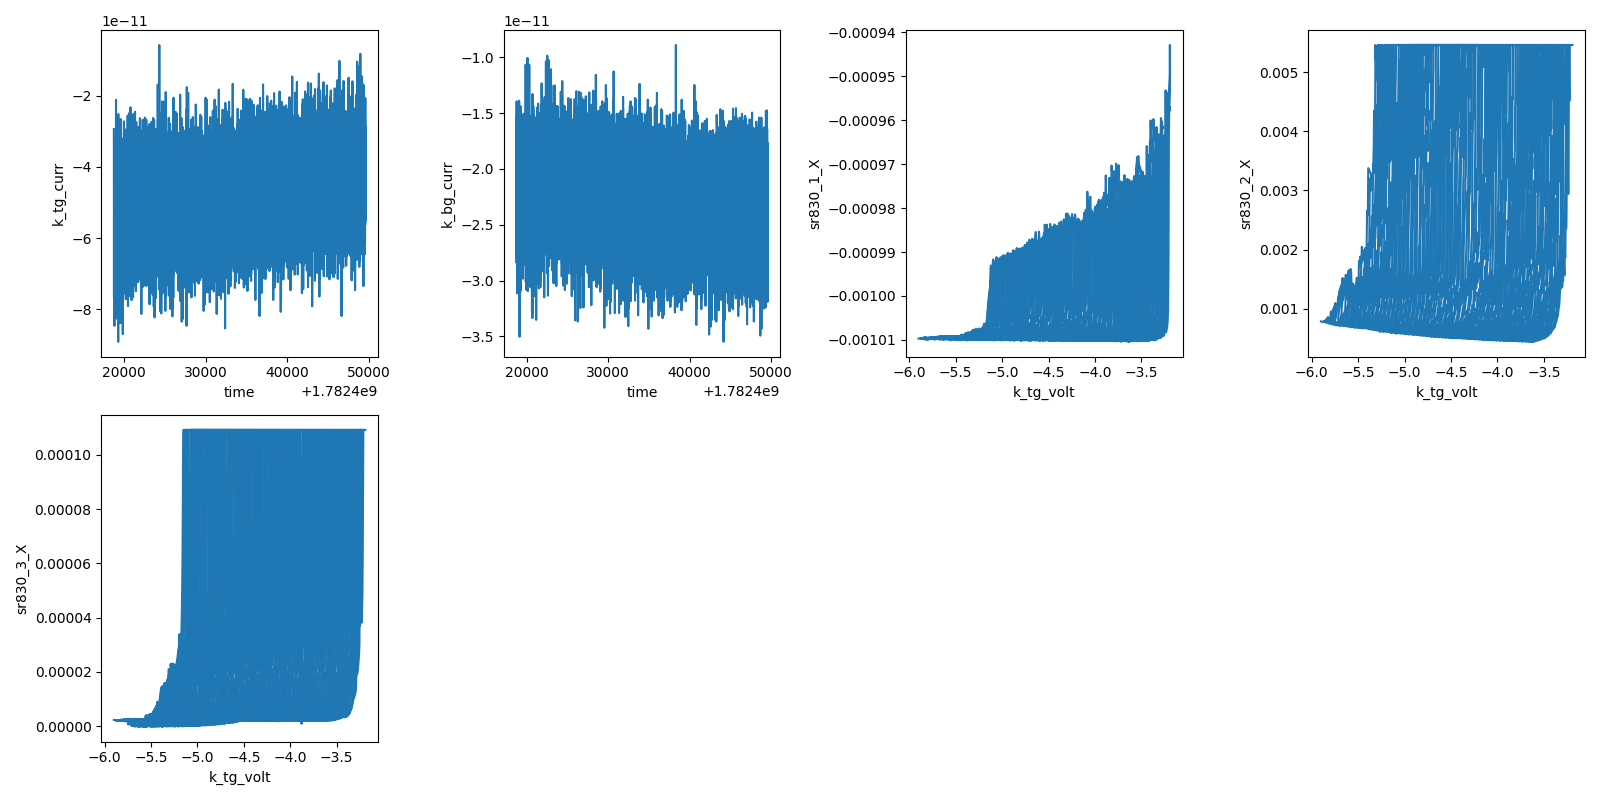

2026-06-25 21:53:11,416 [INFO] Completed in 8h 34m 30s
2026-06-25 21:53:11,417 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\3\data.tsv.gz
2026-06-25 21:53:11,483 [INFO] Ramping k_tg_volt: -3.619 -> -5.36477247080011
2026-06-25 21:53:13,775 [INFO] Ramping k_bg_volt: 2.2665 -> 3.986915985197646
done; gates at optimum, B=-0.360 mT


In [14]:
# === Figure 1 (FINAL v4, supersedes 31, 33, 35) — wide symmetric dome map, 4T sens 0.1 mV ===
# Correction vs cell 35: 4T sensitivity 5 mV -> 0.1 mV (resolve 1 kOhm at 1 nA,
# gain x100 -> 0.1 mV full scale). Rails above ~1 kOhm (near-CNP gap; don't care).
# Symmetric grid unchanged: n[-7,-1] step 0.03 (201) x D[-0.69,-0.40] step 0.0025 (117).
import scipy.constants as cst

B_EFF0 = -0.366e-3   # T (Step 0)

# --- silent-precondition reads ---
T_now = temperature(); B_now = magnet.field()
Vtg_now = k_tg.volt(); Vbg_now = k_bg.volt(); Hv = heater.volt()
print(f"T = {T_now*1e3:.1f} mK     (expect ~34)")
print(f"B = {B_now*1e3:.4f} mT    (expect ~0; will ramp to B_eff0)")
print(f"V_tg = {Vtg_now:.3f} V     (expect -5.365, optimum)")
print(f"V_bg = {Vbg_now:.3f} V     (expect +3.987, optimum)")
print(f"heater = {Hv:.3f} V       (expect 0)")
assert T_now < 0.060, f"T high: {T_now*1e3:.1f} mK"
assert abs(B_now) < 0.005, f"B off-zero at start: {B_now*1e3:.3f} mT"
assert Hv < 0.01, f"heater on: {Hv:.3f} V"

# --- (n,D) calibration: USE EXACTLY ---
N_OFF = -0.362e11 * 1e4
cal_r4 = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2, n_offset=N_OFF)
c_tg, c_bg = cal_r4.c_tg, cal_r4.c_bg
e, eps0 = cst.e, cst.epsilon_0
def nD_to_V(n_cm2, D_Vnm):
    n = np.asarray(n_cm2)*1e4; D = np.asarray(D_Vnm)*1e9
    A = (n - cal_r4.n_offset)*e; B = (D - cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg), (A-B)/(2*c_bg)

# --- AC sense config: 1 nA; 4T sens 0.1 mV (resolve 1 kOhm at 1 nA, gain x100) ---
dc205_1.volt(0.0)
sr830_1.amplitude(0.1)
sr830_2.sensitivity(0.005)    # 2T (5-4) contact monitor ~13 kOhm: keep 5 mV so it doesn't rail
sr830_3.sensitivity(1e-4)     # 4T (30-31) SC channel: 0.1 mV full scale = 1 kOhm ceiling at 1 nA
k_tg.nplci(1); k_bg.nplci(1)

# --- SYMMETRIC grid (unchanged): n fast 0.03, D slow 0.0025 (extremal -> -0.40), boustrophedon ---
n_fast = np.round(np.arange(-1.0, -7.0001, -0.03), 5)            # 201 pts
D_desc = np.round(np.arange(-0.40, -0.69001, -0.0025), 5)
D_slow = D_desc[::-1]                                            # ascending: extremal .. -0.40
vtg_l = []; vbg_l = []; rowlen = []
for i, D0 in enumerate(D_slow):
    nn = n_fast if i % 2 == 0 else n_fast[::-1]
    vt, vb = nD_to_V(nn*1e11, D0)
    vt, vb = sanitize_tg_bg(vt, vb, tg_lims, bg_lims)            # clips extremal-D edge at BG cap
    vtg_l.append(vt); vbg_l.append(vb); rowlen.append(len(vt))
vtg = np.concatenate(vtg_l); vbg = np.concatenate(vbg_l)
print(f"grid: {len(D_slow)} D-rows x up to {len(n_fast)} n = {len(vtg)} pts kept "
      f"(row len {min(rowlen)}-{max(rowlen)}; dome ~27 n x ~28 D pts -- symmetric)")
print(f"V_tg[{vtg.min():.3f},{vtg.max():.3f}]  V_bg[{vbg.min():.3f},{vbg.max():.3f}] (<=4.2)")
assert vbg.max() <= 4.2 and vtg.min() >= -7.0, "validator breach in path!"

meas_config["comment"] = (f"Fig1 FINAL symmetric wide dome map (nD-map); n[-7,-1]e11 fast 0.03 x "
                          f"D[-0.69,-0.40] slow 0.0025 (extremal->-0.40, symmetric); {len(vtg)} pts "
                          f"boustrophedon; delay 1.3; AC 1 nA; 4T sens 0.1 mV (1 kOhm ceiling); "
                          f"B=B_eff0={B_EFF0*1e3:.3f} mT")
s = sweep.AsyncStation(meas_config)
s.add_comment('nD-map')
s.add_comment('Figure 1 (final v4, symmetric, ~8.5h): wide SC dome map at B_eff0; 4T sens 0.1 mV')
s.add_comment(meas_config["comment"])
s.ramp(magnet.field, B_EFF0)
s.ramp(k_tg.volt, vtg[0]); s.ramp(k_bg.volt, vbg[0]); interruptable_sleep(15)
print(f"positioned: B={magnet.field()*1e3:.3f} mT, V_tg={k_tg.volt():.3f}, V_bg={k_bg.volt():.3f}")
xp = k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(magnet.field)
for lia in (sr830_1, sr830_2, sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', k_tg.curr); s.plot('time', k_bg.curr)
s.plot(xp, sr830_1.X)       # current monitor
s.plot(xp, sr830_2.X)       # 2T
s.plot(xp, sr830_3.X)       # 4T Rxx (30-31) -- the dome
try:
    s.multisweep([k_tg.volt, k_bg.volt], [vtg, vbg], delay=1.3)
finally:
    vt_opt, vb_opt = nD_to_V(-5.0e11, -0.64)
    s.ramp(k_tg.volt, float(vt_opt)); s.ramp(k_bg.volt, float(vb_opt))
print(f"done; gates at optimum, B={magnet.field()*1e3:.3f} mT")


## HERA — Heater block START: warm-up + dwell calibration + Tc preview

Fig 1 done (selection: D=−0.64, n=−5.0×10¹¹). Now the **heater (T-axis) block** — the expensive, least-reversible phase. Gates are already at the optimum and B at B_eff0, so we're positioned.

**The block (heat up ONCE, get all T-data, then cool):**
1. **This cell** — warm up to the 6.5 V ceiling (~490 mK) in steps, *settle-gated*. Purpose: (a) **calibrate the per-step thermalization** so I can set the Fig-3 ~100-step ladder dwell empirically (the brief's "gate on settling, not absolute T"); (b) re-confirm the heater→T map; (c) read 4T R(T) at the dome center = a **free Tc preview** (expect R→normal by ~280 mK). ~1.5–2 h.
2. **Fig 3** — R(T,n) map: `multimegasweep`, heater the dense slow axis stepping **down** 6.5→0 V (~100 T-pts, measure-while-cooling), n-line fast at D=−0.64, B=B_eff0.
3. **Fig 4** — repeat the T-map at B_eff0+{1,2,4 mT} (3 more maps; Fig 3 is the 0-field member).
4. **⚑ verify + Fig 5** — cheap base dV/dI, then dV/dI vs (I_dc, T) on the same T-axis.
5. Cool to base → **Fig 2 Fraunhofer** last.

**Scale flag:** the full heater block is large — realistically **~25–35 h** across Figs 3/4/5 (four ~100-pt T-maps + a 2D dV/dI), consistent with the multi-day figure campaign. Each piece checkpoints; nothing locks us in. If you'd rather trim (fewer T-points, fewer Fig-4 fields, coarser dwell), say so and I'll re-scope. **This warm-up cell is the only commitment right now** — it's reversible (cool back anytime) and sets the dwell before the big map.

**Heater discipline (rig card):** ≤1 V steps, equilibrate each; confirm `heater.curr` drawing (asserted). The cell polls (T, R) every 30 s, breaks each step when |dT/dt| < 1 mK/min (or 15 min cap), and prints the settle time. **Watch the fridge MC** — interrupt if T runs away. Preconditions asserted at top (base T, B=B_eff0, gates at optimum, heater off). Leaves heater at 6.5 V for the descending Fig-3 ladder. I'll read the settle times and propose Fig 3 with the calibrated dwell.


In [15]:
# === Heater block — warm-up + dwell calibration + R(T) preview at the optimum ===
# Step the heater up to the ceiling at the dome optimum (gates already here from
# Fig 1). At each step: confirm heater drawing, poll (T, R) until dT/dt settles,
# record. Outputs: (a) per-step settle time -> sets Fig-3 multimegasweep slow_delay;
# (b) heater->T re-confirmation; (c) 4T R(T) at the dome center = a free Tc preview.
# Leaves the heater at the ceiling, positioned for the descending Fig-3 ladder.
import time

# --- silent-precondition reads (optimum, B_eff0, base T, heater off) ---
B_EFF0 = -0.366e-3
T0 = temperature(); B_now = magnet.field()
Vtg = k_tg.volt(); Vbg = k_bg.volt(); Hv = heater.volt()
print(f"T = {T0*1e3:.1f} mK     (expect ~34, base)")
print(f"B = {B_now*1e3:.4f} mT  (expect B_eff0 = {B_EFF0*1e3:.3f})")
print(f"V_tg = {Vtg:.3f}      (expect -5.365, optimum n=-5.0)")
print(f"V_bg = {Vbg:.3f}      (expect +3.987)")
print(f"heater = {Hv:.3f} V    (expect 0)")
assert T0 < 0.060, f"T not at base: {T0*1e3:.1f} mK"
assert abs(B_now - B_EFF0) < 0.0015, f"B off B_eff0: {B_now*1e3:.3f} mT"
assert abs(Vtg-(-5.365)) < 0.010 and abs(Vbg-(+3.987)) < 0.010, "gates off optimum"
assert Hv < 0.01, f"heater already on: {Hv:.3f} V"

# --- AC sense (same as the dome map; 4T resolves 0..1 kOhm) ---
dc205_1.volt(0.0)
sr830_1.amplitude(0.1)          # 1 nA
sr830_2.sensitivity(0.005)
sr830_3.sensitivity(1e-4)       # 0.1 mV, 4T (30-31)
I_bias = 0.1/1e8                # 1 nA
def read_R():                   # 4T Rxx at the optimum, Ohm
    return (sr830_3.X()/100)/I_bias

# --- step up, settle-gated; record (T, R) per step ---
steps = [1.0, 2.0, 3.0, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5]   # finer near the top (larger dT/V, longer settle)
POLL = 30.0           # s between (T,R) reads
MAX_DWELL = 15*60     # s cap per step
SETTLE = 1.0          # mK/min: |dT/dt| below this = settled
ladder = []
print("\nstep  Vh(V)  I_heat(A)   T(mK)   dT/dt(mK/min)  R4T(ohm)  t_settle(s)")
for sp in steps:
    s_ramp_t = time.monotonic()
    heater.volt(sp)                      # substepped at volt.step=5mV
    time.sleep(1.0)
    Ih = heater.curr()
    assert abs(Ih) > 1e-9, f"heater not drawing at {sp} V (open line?): I={Ih:.2e} A"
    Tprev = temperature(); tprev = time.monotonic(); dTdt = 9e9
    while True:
        interruptable_sleep(POLL)
        Tnow = temperature(); tnow = time.monotonic()
        dTdt = (Tnow - Tprev)*1e3 / ((tnow - tprev)/60.0)   # mK/min
        elapsed = tnow - s_ramp_t
        print(f"      {sp:4.1f}  {Ih: .3e}  {Tnow*1e3:6.1f}  {dTdt:+8.2f}        {read_R():7.2f}   {elapsed:5.0f}")
        Tprev, tprev = Tnow, tnow
        if abs(dTdt) < SETTLE or elapsed > MAX_DWELL:
            break
    ladder.append((sp, Ih, temperature(), read_R(), time.monotonic()-s_ramp_t))
    print(f"  -> step {sp:4.1f} V settled: T={temperature()*1e3:.1f} mK, R={read_R():.2f} ohm, "
          f"settle={time.monotonic()-s_ramp_t:.0f} s, |dT/dt|={abs(dTdt):.2f} mK/min")

print("\n=== heater->T ladder (this cooldown) + R(T) at optimum + settle times ===")
print("Vh(V)  T(mK)   R4T(ohm)  settle(s)")
for sp, Ih, T, R, st in ladder:
    print(f"{sp:4.1f}  {T*1e3:6.1f}  {R:7.2f}   {st:5.0f}")
print(f"\nHeater held at {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK. "
      f"Positioned for descending Fig-3 R(T,n) ladder. Max settle informs slow_delay.")


T = 33.5 mK     (expect ~34, base)
B = -0.3831 mT  (expect B_eff0 = -0.366)
V_tg = -5.365      (expect -5.365, optimum n=-5.0)
V_bg = 3.987      (expect +3.987)
heater = 0.000 V    (expect 0)

step  Vh(V)  I_heat(A)   T(mK)   dT/dt(mK/min)  R4T(ohm)  t_settle(s)


Sleeping:   0%|          | 0.0/30.0s []

       1.0   4.222e-05    43.8    +20.50           1.56      32


Sleeping:   0%|          | 0.0/30.0s []

       1.0   4.222e-05    46.3     +5.01           1.27      62


...

       6.5   7.000e-04   478.5     -1.80          43.06     332


Sleeping:   0%|          | 0.0/30.0s []

       6.5   7.000e-04   480.2     +3.42          42.25     362


Sleeping:   0%|          | 0.0/30.0s []

       6.5   7.000e-04   480.3     +0.14          42.95     392
  -> step  6.5 V settled: T=480.3 mK, R=42.92 ohm, settle=392 s, |dT/dt|=0.14 mK/min

=== heater->T ladder (this cooldown) + R(T) at optimum + settle times ===
Vh(V)  T(mK)   R4T(ohm)  settle(s)
 1.0    48.6     0.41     152
 2.0   100.3     0.56     513
 3.0   157.7     2.94     513
 4.0   228.9     5.81     603
 4.5   262.4    17.29     272
 5.0   316.6    38.37     512
 5.5   363.8    40.49     362
 6.0   428.4    42.65     782
 6.5   480.3    42.95     392

Heater held at 6.50 V, T=480.3 mK. Positioned for descending Fig-3 R(T,n) ladder. Max settle informs slow_delay.


## HERA — Figure 3: R(T,n) map at the widest-D line (D=−0.64), B=B_eff0

Warm-up landed: heater→T re-confirmed, and the **R(T) at the optimum previews Tc≈280 mK** (R→0 below ~150 mK, normal ~43 Ω by ~360 mK) — the SC is healthy. Settle times (τ≈2 min) say the dense ladder's 4.4 mK steps thermalize in ~100 s.

**This cell** — the headline T-map. Flavor A `multimegasweep`: heater the **dense slow axis stepping DOWN** (480→34 mK, **100 steps, uniform 4.4 mK** built from the warm-up's measured heater→T), n the **fast axis** at D=−0.64 (n∈[−4.0,−6.5]×10¹¹, 0.02 step, 126 pts — into normal both sides). B held at B_eff0. AC 1 nA, 4T sens 0.1 mV, DC 0. **Measure-while-cooling** (recipe-preferred: the mixture's cooling power settles each descending step). `init_delay=False` (heater already at the 6.5 V ceiling). **slow_delay 90 s** (≳ the calibrated ~100 s settle; per-row T-drift ~2 mK ≪ the 4.4 mK step).

**~7 h** (100 steps × (90 s settle + 126 pts × ~1.3 s) ≈ 7.0 h). Ends with **heater OFF at base** — positioned for Fig 4a, which will ascend from base at B_eff0+1 mT (alternating ladder direction to avoid re-warming between the four field-maps).

**Preconditions (asserted):** heater at the ceiling & drawing (run cell 40 first if not), B=B_eff0. Cell `fp`'s T / fridge-T / heater V & I and plots heater.curr + T live. **Watch the fridge MC for runaway — interrupt (`nb-collab interrupt`) if T spikes.** **Checkpoints:** first ~2 steps (heater drawing, T descending, dome appears on the n-line); then ~hourly (T ladder monotonic, dome suppressing with T). I'll read the map at completion (R(T,n), Tc(n), the dome's T-extent) and propose Fig 4.


In [16]:
# === Figure 3 — R(T, n) map at the widest-D line (D=-0.64), B=B_eff0 ===
# Flavor A: heater the dense slow axis stepping DOWN (measure-while-cooling),
# n-line fast at fixed D. Uniform-T ladder (~100 pts, 480->34 mK) built from the
# warm-up's measured heater->T. Ends heater OFF at base, positioned for Fig 4a.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3

# --- preconditions: heated (~480 mK), B_eff0, heater drawing ---
T_now = temperature(); B_now = magnet.field(); Hv = heater.volt(); Ih = heater.curr()
print(f"T = {T_now*1e3:.1f} mK     (expect ~480, warmed)")
print(f"B = {B_now*1e3:.4f} mT    (expect B_eff0 {B_EFF0*1e3:.3f})")
print(f"heater = {Hv:.3f} V, I = {Ih:.3e} A   (expect ~6.5 V, drawing)")
assert abs(B_now - B_EFF0) < 0.0015, f"B off B_eff0: {B_now*1e3:.3f} mT"
assert Hv > 6.0 and abs(Ih) > 1e-9, "heater not at ceiling / not drawing — run warm-up (cell 40) first"

# --- AC sense (re-assert): 1 nA, 4T 0.1 mV, DC 0 ---
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)

# --- (n,D) calibration ---
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D_Vnm):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D_Vnm)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)

# --- fast axis: n-line at D=-0.64 ---
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3)         # 126 pts, into normal both sides
vt_line,vb_line=nD_to_V(n_line,-0.64)
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all(), "n-line breaches validators"

# --- slow axis: uniform-T descending ladder from the warm-up's heater->T (this cooldown) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(480.0,34.0,100)                   # mK, descending
V_ladder=np.interp(T_targets,T_cal,Vh_cal)              # -> heater V (ends at 0 = base)
print(f"ladder: {len(V_ladder)} steps, heater {V_ladder[0]:.3f}->{V_ladder[-1]:.3f} V "
      f"(T {T_targets[0]:.0f}->{T_targets[-1]:.0f} mK, ~{T_targets[0]-T_targets[1]:.1f} mK/step)")
print(f"n-line: {len(n_line)} pts, D=-0.64, n[-4.0,-6.5]")

meas_config["comment"]=(f"Fig3 R(T,n) Flavor-A map; D=-0.64 widest-D line; B=B_eff0={B_EFF0*1e3:.3f} mT; "
                        f"heater slow {len(V_ladder)}-step uniform-T 480->34 mK (descending, measure-while-cooling); "
                        f"n fast {len(n_line)} pts [-4.0,-6.5]e11 0.02 step; AC 1 nA; 4T 0.1 mV; slow_delay 90 fast_delay 1")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence')
s.add_comment('Figure 3: R(T,n) at widest-D line D=-0.64, B=B_eff0 (Flavor A, heater slow axis)')
s.add_comment(meas_config["comment"])
xp=k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr)      # confirm heater drawing through the run
s.plot('time', temperature)      # T descending ladder
s.plot(xp, sr830_3.X)            # 4T Rxx vs n (live)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=90, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0)             # ensure heater off at base
    # leave gates at optimum for the verify/next steps
    vt_opt,vb_opt=nD_to_V(-5.0e11,-0.64); s.ramp(k_tg.volt,float(vt_opt)); s.ramp(k_bg.volt,float(vb_opt))
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


T = 489.9 mK     (expect ~480, warmed)
B = -0.3451 mT    (expect B_eff0 -0.366)
heater = 6.500 V, I = 7.035e-04 A   (expect ~6.5 V, drawing)


AssertionError: n-line breaches validators

## HERA — Figure 3 (corrected) · **supersedes cell 43 — run THIS**

Bug fix only: cell 43's n-line dropped a `*1e11` (passed n in 1e11-units to `nD_to_V`, which expects cm⁻²), so the points landed at the CNP at D=−0.64 → V_bg≈4.29 V > the 4.2 cap → the validator assert fired (correctly — it caught a bad gate target before any hardware moved). Fixed: `nD_to_V(n_line*1e11, −0.64)` → V_tg∈[−5.47,−5.29], V_bg∈[3.90,4.05], all in range.

**Identical otherwise:** R(T,n) at D=−0.64, B=B_eff0, heater descending 480→34 mK (100 uniform 4.4 mK steps, measure-while-cooling), n-line fast 126 pts, AC 1 nA, 4T 0.1 mV, slow_delay 90 s, init_delay=False, ~7 h, ends heater-off at base. Heater is still at the 6.5 V ceiling from the warm-up (precondition asserts that). **Run this cell; ignore cell 43.** Same checkpoints (first steps, then ~hourly); watch the fridge MC.


In [ ]:
# === Figure 3 — R(T, n) map at the widest-D line (D=-0.64), B=B_eff0 ===
# Flavor A: heater the dense slow axis stepping DOWN (measure-while-cooling),
# n-line fast at fixed D. Uniform-T ladder (~100 pts, 480->34 mK) built from the
# warm-up's measured heater->T. Ends heater OFF at base, positioned for Fig 4a.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3

# --- preconditions: heated (~480 mK), B_eff0, heater drawing ---
T_now = temperature(); B_now = magnet.field(); Hv = heater.volt(); Ih = heater.curr()
print(f"T = {T_now*1e3:.1f} mK     (expect ~480, warmed)")
print(f"B = {B_now*1e3:.4f} mT    (expect B_eff0 {B_EFF0*1e3:.3f})")
print(f"heater = {Hv:.3f} V, I = {Ih:.3e} A   (expect ~6.5 V, drawing)")
assert abs(B_now - B_EFF0) < 0.0015, f"B off B_eff0: {B_now*1e3:.3f} mT"
assert Hv > 6.0 and abs(Ih) > 1e-9, "heater not at ceiling / not drawing — run warm-up (cell 40) first"

# --- AC sense (re-assert): 1 nA, 4T 0.1 mV, DC 0 ---
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)

# --- (n,D) calibration ---
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D_Vnm):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D_Vnm)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)

# --- fast axis: n-line at D=-0.64 ---
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3)         # 126 pts, into normal both sides (1e11 cm^-2 units)
vt_line,vb_line=nD_to_V(n_line*1e11,-0.64)              # *1e11: nD_to_V takes cm^-2
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all(), "n-line breaches validators"

# --- slow axis: uniform-T descending ladder from the warm-up's heater->T (this cooldown) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(480.0,34.0,100)                   # mK, descending
V_ladder=np.interp(T_targets,T_cal,Vh_cal)              # -> heater V (ends at 0 = base)
print(f"ladder: {len(V_ladder)} steps, heater {V_ladder[0]:.3f}->{V_ladder[-1]:.3f} V "
      f"(T {T_targets[0]:.0f}->{T_targets[-1]:.0f} mK, ~{T_targets[0]-T_targets[1]:.1f} mK/step)")
print(f"n-line: {len(n_line)} pts, D=-0.64, n[-4.0,-6.5]")

meas_config["comment"]=(f"Fig3 R(T,n) Flavor-A map; D=-0.64 widest-D line; B=B_eff0={B_EFF0*1e3:.3f} mT; "
                        f"heater slow {len(V_ladder)}-step uniform-T 480->34 mK (descending, measure-while-cooling); "
                        f"n fast {len(n_line)} pts [-4.0,-6.5]e11 0.02 step; AC 1 nA; 4T 0.1 mV; slow_delay 90 fast_delay 1")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence')
s.add_comment('Figure 3: R(T,n) at widest-D line D=-0.64, B=B_eff0 (Flavor A, heater slow axis)')
s.add_comment(meas_config["comment"])
xp=k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr)      # confirm heater drawing through the run
s.plot('time', temperature)      # T descending ladder
s.plot(xp, sr830_3.X)            # 4T Rxx vs n (live)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=90, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0)             # ensure heater off at base
    # leave gates at optimum for the verify/next steps
    vt_opt,vb_opt=nD_to_V(-5.0e11,-0.64); s.ramp(k_tg.volt,float(vt_opt)); s.ramp(k_bg.volt,float(vb_opt))
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


T = 488.6 mK     (expect ~480, warmed)
B = -0.3857 mT    (expect B_eff0 -0.366)
heater = 6.500 V, I = 7.035e-04 A   (expect ~6.5 V, drawing)
ladder: 100 steps, heater 6.497->0.000 V (T 480->34 mK, ~4.5 mK/step)
n-line: 126 pts, D=-0.64, n[-4.0,-6.5]
2026-06-25 23:19:53,491 [INFO] Starting multimegasweep with ID 4
2026-06-25 23:19:53,492 [INFO] Minimum duration 6h 0m 0s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 301s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 300s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


## HERA — Settle test: measure the true equilibration time (for the settled re-do)

**Decision: full settled re-do of the heater block** (rigorous T-axis). Fig 3 (run 4) had a ~50 mK sample-probe lag at 90 s dwell — the dome shape is right but the T-axis is biased low (Tc 223 vs true ~280 mK). To do the re-do right, I need the *actual* dwell, not another guess.

**This cell** parks the heater at the transition midpoint (4.5 V ≈ 262 mK — the most lag-sensitive point) from base and watches **R (the sample-T proxy) equilibrate**, printing (t, T, R) every 15 s for 14 min. The time for R to plateau (within 2%) = the per-step dwell the settled ladder needs. Then returns the heater to 0 (cool back to base for the ascending settled re-do).

~14 min + a brief cool-back. Preconditions asserted (base T, B=B_eff0, gates at optimum, heater off). **Watch the fridge MC.** I'll read the settle time and build the settled Fig 3 (ascending from base, dwell = measured settle + margin, ~50 T-points) — then apply the same dwell to Figs 4/5. Run cell when ready.


In [18]:
# === Settle test — measure the true per-step equilibration time (sets the settled-ladder dwell) ===
# Fig 3 (run 4) showed a ~50 mK sample-probe lag at 90 s dwell. Park the heater at
# the transition midpoint from base and watch R (the sample-T proxy) equilibrate
# -> the time for R to plateau is the dwell the settled re-do needs.
import time

B_EFF0 = -0.366e-3
# --- preconditions: at base, B_eff0, gates at optimum, heater off ---
T0 = temperature(); B_now = magnet.field(); Vtg = k_tg.volt(); Vbg = k_bg.volt(); Hv = heater.volt()
print(f"T={T0*1e3:.1f} mK (expect ~34) B={B_now*1e3:.4f} mT V_tg={Vtg:.3f} V_bg={Vbg:.3f} heater={Hv:.3f} V")
assert T0 < 0.060, f"not at base: {T0*1e3:.1f} mK"
assert abs(B_now-B_EFF0) < 0.0015, "B off B_eff0"
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv < 0.01, "heater not off"

dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)
I_bias = 0.1/1e8
def Rnow(): return (sr830_3.X()/100)/I_bias

def watch(Vset, minutes):
    print(f"\n--- park heater {Vset} V, watch {minutes} min ---")
    t0 = time.monotonic(); heater.volt(Vset); time.sleep(1.0)
    assert abs(heater.curr()) > 1e-9, f"heater not drawing at {Vset} V"
    rec = []
    print(" t(s)   T(mK)   R(ohm)   dR (last)")
    Rprev = None
    while time.monotonic()-t0 < minutes*60:
        interruptable_sleep(15)
        T = temperature(); R = Rnow(); el = time.monotonic()-t0
        dR = (R-Rprev) if Rprev is not None else 0.0
        print(f" {el:5.0f}  {T*1e3:6.1f}  {R:7.2f}   {dR:+6.2f}")
        rec.append((el, T*1e3, R)); Rprev = R
    rec = np.array(rec)
    Rfinal = np.median(rec[-4:,2])
    # settle time = first t where R within 2% of final and stays
    tol = max(0.02*abs(Rfinal), 0.5)
    settled = None
    for el, T, R in rec:
        if abs(R-Rfinal) <= tol:
            settled = el; break
    print(f"  -> {Vset} V: T_final={np.median(rec[-4:,1]):.1f} mK, R_final={Rfinal:.2f} ohm, "
          f"R within 2% by t~{settled:.0f} s")
    return rec

# transition midpoint (most lag-sensitive); ~262 mK at 4.5 V per warm-up
watch(4.5, 14)
heater.volt(0.0)
print(f"\nheater back to 0; cooling to base. T={temperature()*1e3:.1f} mK. "
      f"Settled re-do dwell = the R-plateau time above (with margin).")


T=34.2 mK (expect ~34) B=-0.3901 mT V_tg=-5.365 V_bg=3.987 heater=0.000 V

--- park heater 4.5 V, watch 14 min ---
 t(s)   T(mK)   R(ohm)   dR (last)


Sleeping:   0%|          | 0.0/15.0s []

    22    86.7     0.82    +0.00


Sleeping:   0%|          | 0.0/15.0s []

    37   176.0     0.89    +0.07


...

   818   284.0    34.53    +2.50


Sleeping:   0%|          | 0.0/15.0s []

   833   285.2    32.34    -2.20


Sleeping:   0%|          | 0.0/15.0s []

   848   285.2    32.97    +0.63
  -> 4.5 V: T_final=284.6 mK, R_final=32.65 ohm, R within 2% by t~803 s

heater back to 0; cooling to base. T=285.2 mK. Settled re-do dwell = the R-plateau time above (with margin).


## HERA — Figure 3 (re-do) — R(T,n) at D=−0.64, B=B_eff0: 1τ-dwell, small-step ascending

The fix, your prescription: **~1τ dwell per step + small steps**. At 1τ each step is ~63% thermalized; the un-thermalized remainder is ~0.37×(step), which is tiny because the steps are small → the sample tracks T. No zero-dwell, no full-settle, **no up/down averaging**.

- **τ ≈ 3.5 min** — from the warm-up's own 1 V settles (probe dT/dt<1 mK/min reached in ~510–780 s).
- **slow_delay = 210 s (~1τ)**, **120 uniform-T steps (~3.7 mK each)** → residual per-step lag **~1.4 mK**.
- **Single ascending traverse**, base→480 mK. Ascending from base (we're cooling there now) needs no re-warm, and the 1τ dwell lets T reach the top cleanly. n-line fast at D=−0.64 (126 pts), AC 1 nA, 4T 0.1 mV.

**~12.5 h** (120 × (210 s dwell + ~164 s n-sweep)); waits for base first. This supersedes the dynamic run 4 (which I'll keep as the diagnostic). vs run 4: 90 s dwell (<1τ, under-thermalized) + only 100 pts (bigger steps) → that's what gave the ~80 mK lag.

**Verification (no ambiguous processing):** I'll check the lag directly — compare this run's Tc(optimum) to the prior settled value (~280 mK) and to run 4 (223 mK). If it lands near ~280 with small per-row T-drift, the lag is the few-mK we expect → ship. **Preconditions asserted** (B=B_eff0, gates at optimum, heater off). `fp`'s T/heater and plots heater.curr + T + R live. **Watch the fridge MC.** Checkpoints: first few steps (heater drawing, T tracking, n-line clean), then ~hourly. Run when ready.


B=-0.3760 mT V_tg=-5.365 V_bg=3.987 heater=0.000 V
waiting for base (T<45 mK)...
T=37.9 mK at start (waited 0 min)
ladder: 120 steps, heater 0.000->6.497 V (T 34->480 mK, ~3.7 mK/step); slow_delay=210 s (~1 tau); n-line 126 pts
2026-06-26 11:50:37,463 [INFO] Starting multimegasweep with ID 5
2026-06-26 11:50:37,465 [INFO] Minimum duration 11h 12m 0s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 332s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 344s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 425s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


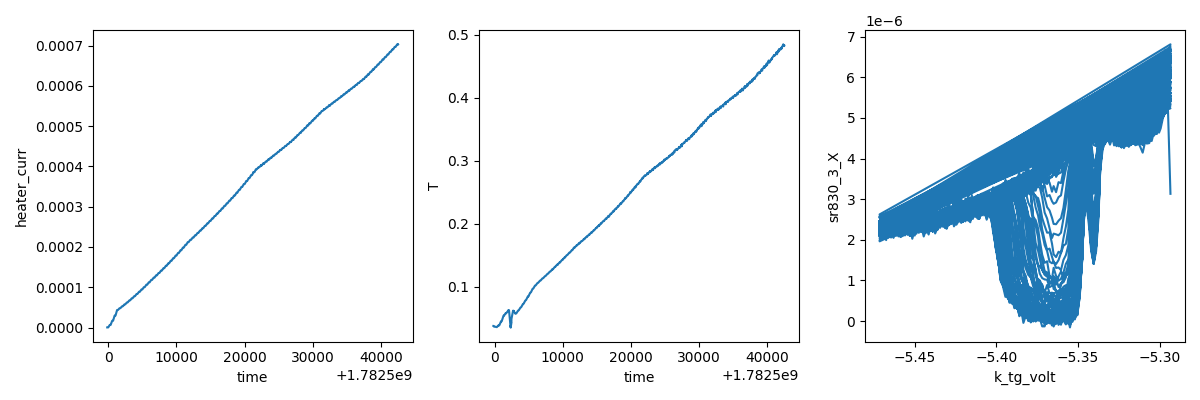

2026-06-26 23:42:26,644 [INFO] Completed in 11h 51m 48s
2026-06-26 23:42:26,645 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\5\data.tsv.gz
2026-06-26 23:42:35,065 [INFO] Ramping k_tg_volt: -5.4715 -> -5.36477247080011
2026-06-26 23:42:35,254 [INFO] Ramping k_bg_volt: 3.8965 -> 3.986915985197646
done; heater 0.00 V, T=482.7 mK, B=-0.371 mT


In [19]:
# === Figure 3 (re-do) — R(T,n) at D=-0.64, B=B_eff0: 1-tau-dwell, small-step ascending ===
# Fix for run 4's lag: ~1 tau dwell per step + small steps -> sample tracks T well.
# tau ~ 3.5 min (warm-up 1 V settles reached probe dT/dt<1 mK/min in ~510-780 s).
# slow_delay = 210 s (~1 tau); 120 uniform-T steps (~3.7 mK) -> residual lag ~1.4 mK.
# Single ascending traverse from base (no re-warm; dwell lets it reach the top). No averaging.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
# --- (n,D) calibration ---
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3)
vt_line,vb_line=nD_to_V(n_line*1e11,-0.64)               # *1e11: nD_to_V takes cm^-2
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all(), "n-line breaches validators"

# --- preconditions: B_eff0, gates at optimum, heater off ---
B_now=magnet.field(); Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
print(f"B={B_now*1e3:.4f} mT V_tg={Vtg:.3f} V_bg={Vbg:.3f} heater={Hv:.3f} V")
assert abs(B_now-B_EFF0)<0.0015, f"B off B_eff0: {B_now*1e3:.3f} mT"
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)

# --- wait for base (settle test left the fridge warm) ---
print("waiting for base (T<45 mK)...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<45*60:
    interruptable_sleep(30)
print(f"T={temperature()*1e3:.1f} mK at start (waited {(time.monotonic()-t0)/60:.0f} min)")

# --- slow axis: uniform-T ascending ladder (small steps), from warm-up heater->T ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(34.0,480.0,120)                    # mK, ascending
V_ladder=np.interp(T_targets,T_cal,Vh_cal)
DWELL=210                                                # s, ~1 tau (tau~3.5 min)
print(f"ladder: {len(V_ladder)} steps, heater {V_ladder[0]:.3f}->{V_ladder[-1]:.3f} V "
      f"(T {T_targets[0]:.0f}->{T_targets[-1]:.0f} mK, ~{T_targets[1]-T_targets[0]:.1f} mK/step); "
      f"slow_delay={DWELL} s (~1 tau); n-line {len(n_line)} pts")

meas_config["comment"]=(f"Fig3 re-do R(T,n); D=-0.64, B=B_eff0={B_EFF0*1e3:.3f} mT; heater ASCENDING "
                        f"{len(V_ladder)}-step uniform-T 34->480 mK (~3.7 mK steps); slow_delay {DWELL}s (~1 tau); "
                        f"n {len(n_line)} pts [-4.0,-6.5]e11; AC 1 nA; 4T 0.1 mV")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence')
s.add_comment('Figure 3 (re-do): R(T,n) at D=-0.64, B_eff0; 1-tau-dwell small-step ascending (no averaging)')
s.add_comment(meas_config["comment"])
xp=k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr); s.plot('time', temperature); s.plot(xp, sr830_3.X)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=DWELL, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0)
    vt_o,vb_o=nD_to_V(-5.0e11,-0.64); s.ramp(k_tg.volt,float(vt_o)); s.ramp(k_bg.volt,float(vb_o))
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


## HERA — Figure 4a: R(T,n) at B = B_eff0 + 1 mT (field member 1 of 3)

Fig 3 done and quantitative (Tc≈235 mK at B_eff0, dome clean; promoted to ana). **Fig 4 = the same R(T,n) at three fixed fields** (B_eff0+{1,2,4 mT}; Fig 3 is the 0-field member) to show the dome collapsing with B. **This cell is the +1 mT member** (~B_c⊥/2 ≈ 1.8 mT, so the dome should be partially suppressed — lower Tc, smaller dome).

**Identical settled method to run 5:** 1τ dwell (210 s) + small uniform-T steps (~3.7 mK), single ascending traverse, D=−0.64, AC 1 nA, 4T 0.1 mV. Field positioned **one-sided** to +0.634 mT and **read back** (logged in the run comment as both the controller field and the true sample field B−B_eff0); held fixed through the map. All Fig-4 members run **ascending** (same direction) so the residual lag is consistent across fields for a clean dome-vs-B comparison.

**~12 h** (waits for base first, ~1 h cool from Fig 3's top). **Scale flag:** the full Fig 4 (three fields) is **~36–39 h** at full resolution. The dome weakens with B, so the +2 and +4 mT members have little/no SC to resolve — **I can trim those to fewer T-points (or a narrower n-line) to save ~half the time** without losing the B_c(T) trend. Tell me if you'd rather I trim the higher-field members; otherwise I'll run them at full res. Preconditions asserted (gates at optimum, heater off, field on target). **Watch the fridge MC.** Checkpoints: first steps, then ~hourly. Run cell when ready.


In [ ]:
# === Figure 4a — R(T,n) at B = B_eff0 + 1 mT, D=-0.64 (field member of the T-block) ===
# Same settled method as Fig 3 (run 5): 1 tau dwell (210 s) + small uniform-T steps,
# single ascending traverse. Field held fixed during the map; positioned one-sided,
# read back. Shows the SC dome partially suppressed at ~B_c/2.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
B_TARGET = B_EFF0 + 1.0e-3        # = +0.634 mT (B_eff0 + 1 mT)

# --- (n,D) calibration + n-line ---
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3)
vt_line,vb_line=nD_to_V(n_line*1e11,-0.64)
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all()

# --- preconditions: gates at optimum, heater off ---
Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
print(f"V_tg={Vtg:.3f} V_bg={Vbg:.3f} heater={Hv:.3f} V; B now={magnet.field()*1e3:.4f} mT")
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)

# --- position field (one-sided ramp to target), settle, read back ---
print(f"ramping magnet to B_eff0+1mT = {B_TARGET*1e3:.3f} mT ...")
magnet.field(B_TARGET); interruptable_sleep(20)
B_read = magnet.field()
print(f"magnet at {B_read*1e3:.4f} mT (target {B_TARGET*1e3:.3f}); true sample field = B - B_eff0 = {(B_read-B_EFF0)*1e3:.3f} mT")
assert abs(B_read-B_TARGET)<0.2e-3, f"field off target: {B_read*1e3:.3f} mT"

# --- wait for base ---
print("waiting for base (T<45 mK)...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<60*60:
    interruptable_sleep(30)
print(f"T={temperature()*1e3:.1f} mK at start (waited {(time.monotonic()-t0)/60:.0f} min)")

# --- ladder (same as Fig 3) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(34.0,480.0,120); V_ladder=np.interp(T_targets,T_cal,Vh_cal); DWELL=210
print(f"ladder {len(V_ladder)} steps, slow_delay {DWELL}s (~1 tau); n-line {len(n_line)} pts; B held {B_read*1e3:.3f} mT")

meas_config["comment"]=(f"Fig4a R(T,n); D=-0.64; B={B_read*1e3:.3f} mT (B_eff0+1mT, true field {(B_read-B_EFF0)*1e3:.2f} mT); "
                        f"heater ascending {len(V_ladder)}-step uniform-T 34->480 mK; slow_delay {DWELL}s (~1 tau); "
                        f"n {len(n_line)} pts; AC 1 nA; 4T 0.1 mV; B_eff0={B_EFF0*1e3:.3f} mT")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence')
s.add_comment('Figure 4a: R(T,n) at B_eff0+1mT, D=-0.64; 1-tau-dwell small-step ascending')
s.add_comment(meas_config["comment"])
xp=k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr); s.plot('time', temperature); s.plot(xp, sr830_3.X)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=DWELL, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0)
    vt_o,vb_o=nD_to_V(-5.0e11,-0.64); s.ramp(k_tg.volt,float(vt_o)); s.ramp(k_bg.volt,float(vb_o))
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


## HERA — Figure 4a (capped at 350 mK) · **supersedes cell 55 — run THIS**

Per your point: the field suppresses Tc, so the finite-field transition sits well below the zero-field 235 mK — no need to climb to 480 mK. **Capped the ladder at 350 mK** (clear normal baseline above even the zero-field Tc; +1/+2/+4 mT transitions are all lower). Same 3.7 mK step density → **86 points, ~8.9 h** (was 120 pts / 12 h).

Everything else identical: R(T,n) at **B_eff0+1 mT** (= +0.634 mT, positioned one-sided + read back), D=−0.64, 1τ dwell (210 s) + small uniform-T steps, single ascending traverse, AC 1 nA, 4T 0.1 mV. Field held fixed; logged as controller + true (B−B_eff0) field. All Fig-4 members ascending for consistent lag.

**Applying the same 350 mK cap to 4b (+2 mT) and 4c (+4 mT)** — and there the dome is near-gone, so I'll also trim those to fewer T-points (just enough to show the suppressed/absent transition). With the cap, **full Fig 4 drops to ~24–28 h**. ~8.9 h for this member; waits for base first (~1 h cool from Fig 3's top). Preconditions asserted; watch the fridge MC. **Run cell — ignore cell 55.**


In [ ]:
# === Figure 4a — R(T,n) at B = B_eff0 + 1 mT, D=-0.64 (field member of the T-block) ===
# Same settled method as Fig 3 (run 5): 1 tau dwell (210 s) + small uniform-T steps,
# single ascending traverse. Field held fixed during the map; positioned one-sided,
# read back. Shows the SC dome partially suppressed at ~B_c/2.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
B_TARGET = B_EFF0 + 1.0e-3        # = +0.634 mT (B_eff0 + 1 mT)

# --- (n,D) calibration + n-line ---
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3)
vt_line,vb_line=nD_to_V(n_line*1e11,-0.64)
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all()

# --- preconditions: gates at optimum, heater off ---
Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
print(f"V_tg={Vtg:.3f} V_bg={Vbg:.3f} heater={Hv:.3f} V; B now={magnet.field()*1e3:.4f} mT")
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)

# --- position field (one-sided ramp to target), settle, read back ---
print(f"ramping magnet to B_eff0+1mT = {B_TARGET*1e3:.3f} mT ...")
magnet.field(B_TARGET); interruptable_sleep(20)
B_read = magnet.field()
print(f"magnet at {B_read*1e3:.4f} mT (target {B_TARGET*1e3:.3f}); true sample field = B - B_eff0 = {(B_read-B_EFF0)*1e3:.3f} mT")
assert abs(B_read-B_TARGET)<0.2e-3, f"field off target: {B_read*1e3:.3f} mT"

# --- wait for base ---
print("waiting for base (T<45 mK)...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<60*60:
    interruptable_sleep(30)
print(f"T={temperature()*1e3:.1f} mK at start (waited {(time.monotonic()-t0)/60:.0f} min)")

# --- ladder (same as Fig 3) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(34.0,350.0,86); V_ladder=np.interp(T_targets,T_cal,Vh_cal); DWELL=210   # cap 350 mK: field suppresses Tc below the zero-field 235 mK
print(f"ladder {len(V_ladder)} steps (34->350 mK cap, ~3.7 mK), slow_delay {DWELL}s (~1 tau); n-line {len(n_line)} pts; B held {B_read*1e3:.3f} mT")

meas_config["comment"]=(f"Fig4a R(T,n); D=-0.64; B={B_read*1e3:.3f} mT (B_eff0+1mT, true field {(B_read-B_EFF0)*1e3:.2f} mT); "
                        f"heater ascending {len(V_ladder)}-step uniform-T 34->350 mK (field-suppressed Tc); slow_delay {DWELL}s (~1 tau); "
                        f"n {len(n_line)} pts; AC 1 nA; 4T 0.1 mV; B_eff0={B_EFF0*1e3:.3f} mT")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence')
s.add_comment('Figure 4a: R(T,n) at B_eff0+1mT, D=-0.64; 1-tau-dwell small-step ascending')
s.add_comment(meas_config["comment"])
xp=k_tg.volt
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr); s.plot('time', temperature); s.plot(xp, sr830_3.X)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=DWELL, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0)
    vt_o,vb_o=nD_to_V(-5.0e11,-0.64); s.ramp(k_tg.volt,float(vt_o)); s.ramp(k_bg.volt,float(vb_o))
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


V_tg=-5.365 V_bg=3.987 heater=0.000 V; B now=-0.3477 mT
ramping magnet to B_eff0+1mT = 0.634 mT ...


Sleeping:   0%|          | 0.0/20.0s []

magnet at 0.6356 mT (target 0.634); true sample field = B - B_eff0 = 1.002 mT
waiting for base (T<45 mK)...


Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

...

Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

T=0.0 mK at start (waited 8 min)
ladder 86 steps (34->350 mK cap, ~3.7 mK), slow_delay 210s (~1 tau); n-line 126 pts; B held 0.636 mT
2026-06-26 23:59:13,707 [INFO] Starting multimegasweep with ID 6
2026-06-26 23:59:13,708 [INFO] Minimum duration 8h 1m 36s


## HERA — Figure 4b: R(T,n) at B = B_eff0 + 2 mT (field member 2; near B_c)

Fig 4a done: Tc(+1mT)=166 mK (from 235 at B_eff0), promoted to ana. **This is +2 mT** — near B_c⊥ (≈1.8 mT), so the SC should be nearly gone (Step-0 field-kill: ~half-normal at base by ~2 mT). Expect a shallow/low transition or none.

**Trimmed** per your guidance: cap **300 mK**, **~55 points** (the dome is mostly gone; less to resolve), same 1τ dwell (210 s) + small steps, single ascending. Field +1.634 mT — **no zero-cross** (from +0.634), so little ramp heating; still, I added a **post-field-ramp R-settle** (wait for R(optimum) to plateau, not just probe T) to avoid the run-6 startup transient. ~5.7 h.

Field positioned one-sided + read back (logged controller + true field). Preconditions asserted. Watch the fridge MC. Run when ready; I read it + propose 4c (+4 mT, shorter — fully normal).


B now 0.6414 mT; ramping to B_eff0+2mT = 1.634 mT ...


Sleeping:   0%|          | 0.0/20.0s []

magnet at 1.6219 mT (true field 1.99 mT)
waiting for base (T<45 mK)...
T=33.8 mK; now waiting for R(optimum) to plateau (sample settle)...


Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

...

Sleeping:   0%|          | 0.0/30.0s []

  R settled: 9.35 ohm (dR/dt=+1.04/min), T=33.7 mK
ladder 55 steps (34->300 mK, ~4.9 mK), slow_delay 210s; B held 1.622 mT
2026-06-27 11:29:31,238 [INFO] Starting multimegasweep with ID 7
2026-06-27 11:29:31,239 [INFO] Minimum duration 5h 8m 0s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 304s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 448s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 303s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


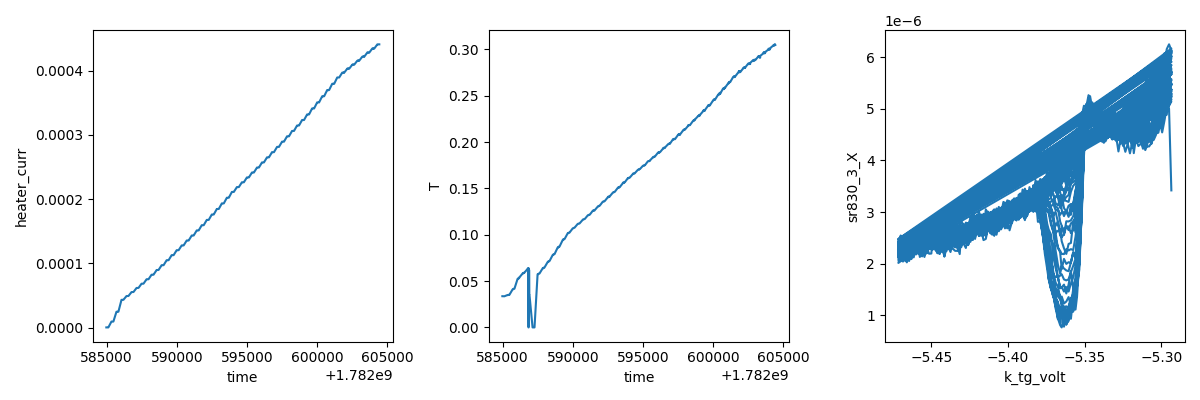

2026-06-27 16:53:46,618 [INFO] Completed in 5h 24m 14s
2026-06-27 16:53:46,619 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\7\data.tsv.gz
2026-06-27 16:53:52,839 [INFO] Ramping k_tg_volt: -5.4715 -> -5.36477247080011
2026-06-27 16:53:53,032 [INFO] Ramping k_bg_volt: 3.8965 -> 3.986915985197646
done; heater 0.00 V, T=304.9 mK, B=1.633 mT


In [21]:
# === Figure 4b — R(T,n) at B = B_eff0 + 2 mT, D=-0.64 (near B_c -> dome near-gone) ===
# Same 1-tau settled ascending method. Field +1.634 mT (no zero-cross from +0.634).
# Trimmed: cap 300 mK, ~55 pts. Adds a post-field-ramp R-settle (wait for the
# sample/R to plateau, not just probe T) to avoid the run-6 startup transient.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
B_TARGET = B_EFF0 + 2.0e-3        # = +1.634 mT (B_eff0 + 2 mT)
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3); vt_line,vb_line=nD_to_V(n_line*1e11,-0.64)
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all()
vt_opt,vb_opt=[float(x) for x in nD_to_V(-5.0e11,-0.64)]

Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)
I_bias=0.1/1e8
def Ropt(): return (sr830_3.X()/100)/I_bias

# --- position field (one-sided, increasing |B|, no zero-cross), read back ---
print(f"B now {magnet.field()*1e3:.4f} mT; ramping to B_eff0+2mT = {B_TARGET*1e3:.3f} mT ...")
magnet.field(B_TARGET); interruptable_sleep(20)
B_read=magnet.field(); print(f"magnet at {B_read*1e3:.4f} mT (true field {(B_read-B_EFF0)*1e3:.2f} mT)")
assert abs(B_read-B_TARGET)<0.2e-3, f"field off target: {B_read*1e3:.3f} mT"

# --- wait for base, THEN R-settle (sample plateau after the field ramp) ---
print("waiting for base (T<45 mK)...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<60*60: interruptable_sleep(30)
print(f"T={temperature()*1e3:.1f} mK; now waiting for R(optimum) to plateau (sample settle)...")
Rp=Ropt(); tp=time.monotonic(); ok=0
while True:
    interruptable_sleep(30); Rn=Ropt(); tn=time.monotonic(); dRdt=(Rn-Rp)/((tn-tp)/60); Rp,tp=Rn,tn
    ok = ok+1 if abs(dRdt)<0.4 else 0
    if ok>=2 or tn-t0>15*60: print(f"  R settled: {Ropt():.2f} ohm (dR/dt={dRdt:+.2f}/min), T={temperature()*1e3:.1f} mK"); break

# --- ladder: cap 300 mK, ~55 pts (dome near-gone) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(34.0,300.0,55); V_ladder=np.interp(T_targets,T_cal,Vh_cal); DWELL=210
print(f"ladder {len(V_ladder)} steps (34->300 mK, ~{T_targets[1]-T_targets[0]:.1f} mK), slow_delay {DWELL}s; B held {B_read*1e3:.3f} mT")

meas_config["comment"]=(f"Fig4b R(T,n); D=-0.64; B={B_read*1e3:.3f} mT (B_eff0+2mT, true {(B_read-B_EFF0)*1e3:.2f} mT); "
                        f"ascending {len(V_ladder)}-step 34->300 mK; slow_delay {DWELL}s (~1 tau); n {len(n_line)} pts; "
                        f"AC 1 nA; 4T 0.1 mV; B_eff0={B_EFF0*1e3:.3f} mT; post-ramp R-settled")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence'); s.add_comment('Figure 4b: R(T,n) at B_eff0+2mT, D=-0.64; 1-tau settled, R-settled start')
s.add_comment(meas_config["comment"])
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr); s.plot('time', temperature); s.plot(k_tg.volt, sr830_3.X)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=DWELL, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0); s.ramp(k_tg.volt,vt_opt); s.ramp(k_bg.volt,vb_opt)
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


## HERA — Figure 4c: R(T,n) at B = B_eff0 + 4 mT (field member 3 of 3 — the normal endpoint)

Fig 4b done: Tc(+2mT)=113 mK, floor 11.6 Ω. **This is +4 mT** — ~2.2× B_c⊥, so the SC should be fully gone (flat normal R(T,n), no dome). This is the "normal" endpoint of the dome-collapse sequence.

**Short** (it just confirms no SC): cap **200 mK**, **~25 points**, same 1τ settled method + post-field-ramp R-settle. Field +3.634 mT (no zero-cross from +1.634). ~2.6 h. Field positioned one-sided + read back.

After this I ramp the field back to **B_eff0** (decreasing |B| toward 0, one-sided) and build the **Fig 4 composite** (Tc-vs-B + the dome collapse across 0/1/2/4 mT), then move to **Fig 5** (the dV/dI verify + dV/dI vs I,T at the optimum, B_eff0). Preconditions asserted; watch the fridge MC. Run when ready.


In [ ]:
# === Figure 4c — R(T,n) at B = B_eff0 + 4 mT, D=-0.64 (2.2x B_c -> fully normal) ===
# Same 1-tau settled ascending method. Field +3.634 mT (no zero-cross from +1.634).
# Trimmed: cap 200 mK, ~25 pts (endpoint: confirm no SC -> flat normal R).
# Post-field-ramp R-settle as in 4b.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
B_TARGET = B_EFF0 + 4.0e-3        # = +3.634 mT (B_eff0 + 4 mT)
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3); vt_line,vb_line=nD_to_V(n_line*1e11,-0.64)
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all()
vt_opt,vb_opt=[float(x) for x in nD_to_V(-5.0e11,-0.64)]

Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)
I_bias=0.1/1e8
def Ropt(): return (sr830_3.X()/100)/I_bias

# --- position field (one-sided, increasing |B|, no zero-cross), read back ---
print(f"B now {magnet.field()*1e3:.4f} mT; ramping to B_eff0+4mT = {B_TARGET*1e3:.3f} mT ...")
magnet.field(B_TARGET); interruptable_sleep(20)
B_read=magnet.field(); print(f"magnet at {B_read*1e3:.4f} mT (true field {(B_read-B_EFF0)*1e3:.2f} mT)")
assert abs(B_read-B_TARGET)<0.2e-3, f"field off target: {B_read*1e3:.3f} mT"

# --- wait for base, THEN R-settle (sample plateau after the field ramp) ---
print("waiting for base (T<45 mK)...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<60*60: interruptable_sleep(30)
print(f"T={temperature()*1e3:.1f} mK; now waiting for R(optimum) to plateau (sample settle)...")
Rp=Ropt(); tp=time.monotonic(); ok=0
while True:
    interruptable_sleep(30); Rn=Ropt(); tn=time.monotonic(); dRdt=(Rn-Rp)/((tn-tp)/60); Rp,tp=Rn,tn
    ok = ok+1 if abs(dRdt)<0.4 else 0
    if ok>=2 or tn-t0>15*60: print(f"  R settled: {Ropt():.2f} ohm (dR/dt={dRdt:+.2f}/min), T={temperature()*1e3:.1f} mK"); break

# --- ladder: cap 200 mK, ~25 pts (endpoint: confirm flat normal, no SC) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(34.0,200.0,25); V_ladder=np.interp(T_targets,T_cal,Vh_cal); DWELL=210
print(f"ladder {len(V_ladder)} steps (34->200 mK, ~{T_targets[1]-T_targets[0]:.1f} mK), slow_delay {DWELL}s; B held {B_read*1e3:.3f} mT")

meas_config["comment"]=(f"Fig4c R(T,n); D=-0.64; B={B_read*1e3:.3f} mT (B_eff0+4mT, true {(B_read-B_EFF0)*1e3:.2f} mT); "
                        f"ascending {len(V_ladder)}-step 34->200 mK; slow_delay {DWELL}s (~1 tau); n {len(n_line)} pts; "
                        f"AC 1 nA; 4T 0.1 mV; B_eff0={B_EFF0*1e3:.3f} mT; post-ramp R-settled")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence'); s.add_comment('Figure 4c: R(T,n) at B_eff0+4mT, D=-0.64; 1-tau settled, R-settled start')
s.add_comment(meas_config["comment"])
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr); s.plot('time', temperature); s.plot(k_tg.volt, sr830_3.X)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=DWELL, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0); s.ramp(k_tg.volt,vt_opt); s.ramp(k_bg.volt,vb_opt)
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


## HERA — Figure 4 (+1.25 mT): intermediate field to resolve the dome collapse

**Drop +4 mT (cell 63 — do NOT run it):** at +2 mT the SC is already essentially gone (Tc 113 mK, floor ~12 Ω), so +4 mT carries no information. Instead, fill the collapse with intermediate fields. We have 0/+1/+2 mT (Tc 235/166/113); this takes **+1.25 mT** (true field), in the steep region between +1 and +2 mT — the most informative point for the B_c(T) curve.

Same 1τ settled method (210 s dwell, small steps, single ascending), D=−0.64, R-settled start. Cap **325 mK**, **~65 points**. Field controller +0.884 mT (= B_eff0+1.25 mT), positioned by **decreasing |B| from the current +1.634 mT** (one-sided toward 0, no zero-cross) and read back. ~6.8 h.

**Plan:** after this I take **+0.5 mT** (fills the 0→1 mT gap) for a clean 5-point dome-collapse (0, 0.5, 1, 1.25, 2 mT), then ramp back to B_eff0 for Fig 5. Preconditions asserted; watch the fridge MC. Run this cell (not 63) when ready.


B now 1.6411 mT; ramping to B_eff0+1.25mT = 0.884 mT ...


Sleeping:   0%|          | 0.0/20.0s []

magnet at 0.8719 mT (true field 1.24 mT)
waiting for base (T<45 mK)...


Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

...

Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

  R settled: 13.30 ohm (dR/dt=-0.60/min), T=42.5 mK
ladder 65 steps (34->325 mK, ~4.5 mK), slow_delay 210s; B held 0.872 mT
2026-06-27 17:19:35,758 [INFO] Starting multimegasweep with ID 8
2026-06-27 17:19:35,759 [INFO] Minimum duration 6h 4m 0s


2026-06-27 18:06:05,368 [WARNING] ID 8 INTERRUPTED
2026-06-27 18:06:05,370 [WARNING] ID 8 INTERRUPTED


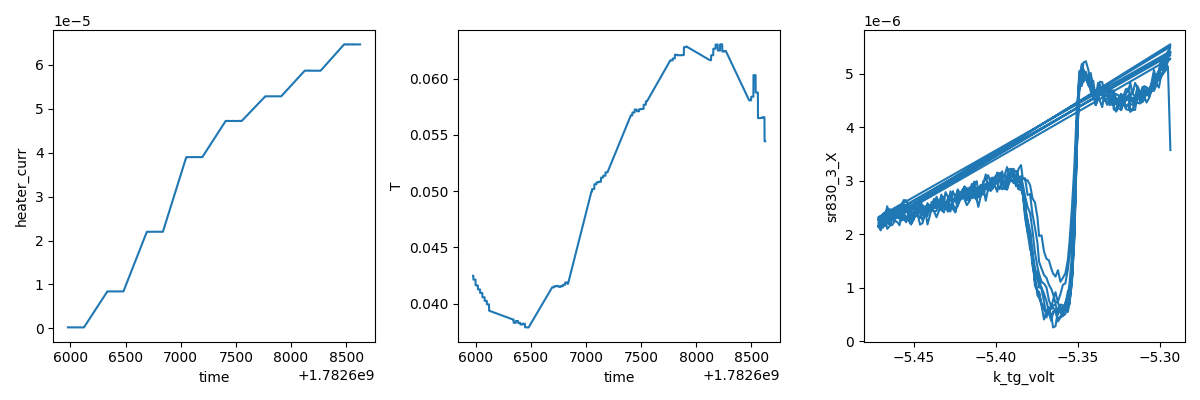

2026-06-27 18:06:06,028 [INFO] Completed in 0h 46m 29s
2026-06-27 18:06:06,030 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\8\data.tsv.gz
2026-06-27 18:06:07,909 [INFO] Ramping k_tg_volt: -5.2935 -> -5.36477247080011
2026-06-27 18:06:08,068 [INFO] Ramping k_bg_volt: 4.047 -> 3.986915985197646
done; heater 0.00 V, T=59.3 mK, B=0.883 mT


In [22]:
# === Figure 4 (+1.25 mT) — R(T,n) at B = B_eff0 + 1.25 mT, D=-0.64 (intermediate field to fill the collapse) ===
# Same 1-tau settled ascending method. Field +0.884 mT controller (decreasing |B| from +1.634, no zero-cross).
# Adds a post-field-ramp R-settle (wait for the
# sample/R to plateau, not just probe T) to avoid the run-6 startup transient.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
B_TARGET = B_EFF0 + 1.25e-3        # = +0.884 mT (B_eff0 + 1.25 mT)
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3); vt_line,vb_line=nD_to_V(n_line*1e11,-0.64)
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all()
vt_opt,vb_opt=[float(x) for x in nD_to_V(-5.0e11,-0.64)]

Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)
I_bias=0.1/1e8
def Ropt(): return (sr830_3.X()/100)/I_bias

# --- position field (one-sided, increasing |B|, no zero-cross), read back ---
print(f"B now {magnet.field()*1e3:.4f} mT; ramping to B_eff0+1.25mT = {B_TARGET*1e3:.3f} mT ...")
magnet.field(B_TARGET); interruptable_sleep(20)
B_read=magnet.field(); print(f"magnet at {B_read*1e3:.4f} mT (true field {(B_read-B_EFF0)*1e3:.2f} mT)")
assert abs(B_read-B_TARGET)<0.2e-3, f"field off target: {B_read*1e3:.3f} mT"

# --- wait for base, THEN R-settle (sample plateau after the field ramp) ---
print("waiting for base (T<45 mK)...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<60*60: interruptable_sleep(30)
print(f"T={temperature()*1e3:.1f} mK; now waiting for R(optimum) to plateau (sample settle)...")
Rp=Ropt(); tp=time.monotonic(); ok=0
while True:
    interruptable_sleep(30); Rn=Ropt(); tn=time.monotonic(); dRdt=(Rn-Rp)/((tn-tp)/60); Rp,tp=Rn,tn
    ok = ok+1 if abs(dRdt)<0.4 else 0
    if ok>=2 or tn-t0>15*60: print(f"  R settled: {Ropt():.2f} ohm (dR/dt={dRdt:+.2f}/min), T={temperature()*1e3:.1f} mK"); break

# --- ladder: cap 325 mK, ~65 pts (intermediate field) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(34.0,325.0,65); V_ladder=np.interp(T_targets,T_cal,Vh_cal); DWELL=210
print(f"ladder {len(V_ladder)} steps (34->325 mK, ~{T_targets[1]-T_targets[0]:.1f} mK), slow_delay {DWELL}s; B held {B_read*1e3:.3f} mT")

meas_config["comment"]=(f"Fig4-125 R(T,n); D=-0.64; B={B_read*1e3:.3f} mT (B_eff0+1.25mT, true {(B_read-B_EFF0)*1e3:.2f} mT); "
                        f"ascending {len(V_ladder)}-step 34->325 mK; slow_delay {DWELL}s (~1 tau); n {len(n_line)} pts; "
                        f"AC 1 nA; 4T 0.1 mV; B_eff0={B_EFF0*1e3:.3f} mT; post-ramp R-settled")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence'); s.add_comment('Figure 4 (+1.25 mT): R(T,n) at B_eff0+1.25mT, D=-0.64; 1-tau settled, R-settled start')
s.add_comment(meas_config["comment"])
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr); s.plot('time', temperature); s.plot(k_tg.volt, sr830_3.X)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=DWELL, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0); s.ramp(k_tg.volt,vt_opt); s.ramp(k_bg.volt,vb_opt)
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


In [23]:
heater.volt(0)

In [26]:
heater.curr()

1.936619e-07

In [27]:
interruptable_sleep(3600)

Sleeping:   0%|          | 0.0/3600.0s []

B now 0.8730 mT; ramping to B_eff0+1.25mT = 0.884 mT ...


Sleeping:   0%|          | 0.0/20.0s []

magnet at 0.9030 mT (true field 1.27 mT)
waiting for base (T<45 mK)...
T=33.6 mK; now waiting for R(optimum) to plateau (sample settle)...


Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

...

Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

  R settled: 3.91 ohm (dR/dt=-0.07/min), T=33.6 mK
ladder 65 steps (34->325 mK, ~4.5 mK), slow_delay 210s; B held 0.903 mT
2026-06-27 19:14:08,245 [INFO] Starting multimegasweep with ID 9
2026-06-27 19:14:08,246 [INFO] Minimum duration 6h 4m 0s


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 301s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


C:\Users\toploader\measurement_env\.venv\Lib\site-packages\qcodes\parameters\command.py:213: StaleThermometryWarning: T_fridge: freshest logfile (Fridge_MixingCh_low.txt) is 300s old (>300s) — dead worker / wrong probe? T may be stale
  return self.exec_function(*args)


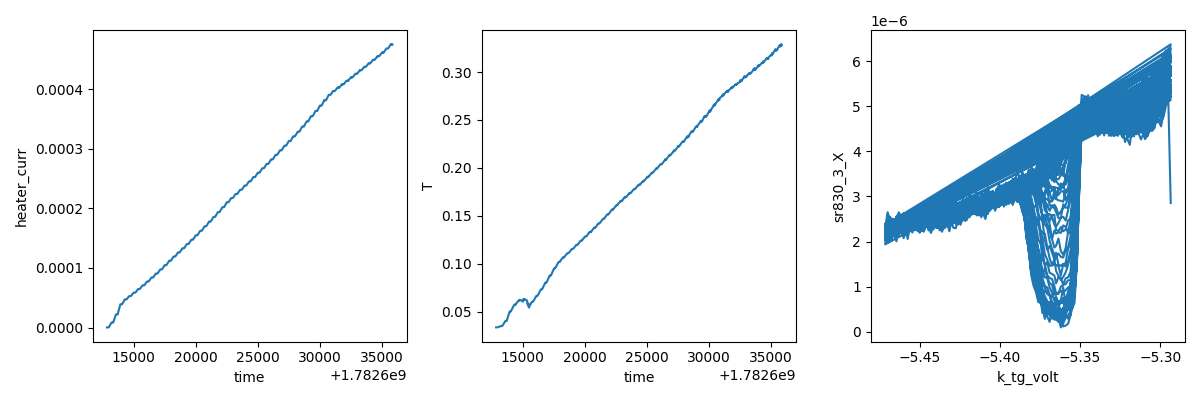

2026-06-28 01:37:42,145 [INFO] Completed in 6h 23m 33s
2026-06-28 01:37:42,145 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\9\data.tsv.gz
2026-06-28 01:37:48,646 [INFO] Ramping k_tg_volt: -5.4715 -> -5.36477247080011
2026-06-28 01:37:48,838 [INFO] Ramping k_bg_volt: 3.8965 -> 3.986915985197646
done; heater 0.00 V, T=328.0 mK, B=0.857 mT


In [28]:
# === Figure 4 (+1.25 mT) — R(T,n) at B = B_eff0 + 1.25 mT, D=-0.64 (intermediate field to fill the collapse) ===
# Same 1-tau settled ascending method. Field +0.884 mT controller (decreasing |B| from +1.634, no zero-cross).
# Adds a post-field-ramp R-settle (wait for the
# sample/R to plateau, not just probe T) to avoid the run-6 startup transient.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
B_TARGET = B_EFF0 + 1.25e-3        # = +0.884 mT (B_eff0 + 1.25 mT)
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3); vt_line,vb_line=nD_to_V(n_line*1e11,-0.64)
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all()
vt_opt,vb_opt=[float(x) for x in nD_to_V(-5.0e11,-0.64)]

Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)
I_bias=0.1/1e8
def Ropt(): return (sr830_3.X()/100)/I_bias

# --- position field (one-sided, increasing |B|, no zero-cross), read back ---
print(f"B now {magnet.field()*1e3:.4f} mT; ramping to B_eff0+1.25mT = {B_TARGET*1e3:.3f} mT ...")
magnet.field(B_TARGET); interruptable_sleep(20)
B_read=magnet.field(); print(f"magnet at {B_read*1e3:.4f} mT (true field {(B_read-B_EFF0)*1e3:.2f} mT)")
assert abs(B_read-B_TARGET)<0.2e-3, f"field off target: {B_read*1e3:.3f} mT"

# --- wait for base, THEN R-settle (sample plateau after the field ramp) ---
print("waiting for base (T<45 mK)...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<60*60: interruptable_sleep(30)
print(f"T={temperature()*1e3:.1f} mK; now waiting for R(optimum) to plateau (sample settle)...")
Rp=Ropt(); tp=time.monotonic(); ok=0
while True:
    interruptable_sleep(30); Rn=Ropt(); tn=time.monotonic(); dRdt=(Rn-Rp)/((tn-tp)/60); Rp,tp=Rn,tn
    ok = ok+1 if abs(dRdt)<0.4 else 0
    if ok>=2 or tn-t0>15*60: print(f"  R settled: {Ropt():.2f} ohm (dR/dt={dRdt:+.2f}/min), T={temperature()*1e3:.1f} mK"); break

# --- ladder: cap 325 mK, ~65 pts (intermediate field) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(34.0,325.0,65); V_ladder=np.interp(T_targets,T_cal,Vh_cal); DWELL=210
print(f"ladder {len(V_ladder)} steps (34->325 mK, ~{T_targets[1]-T_targets[0]:.1f} mK), slow_delay {DWELL}s; B held {B_read*1e3:.3f} mT")

meas_config["comment"]=(f"Fig4-125 R(T,n); D=-0.64; B={B_read*1e3:.3f} mT (B_eff0+1.25mT, true {(B_read-B_EFF0)*1e3:.2f} mT); "
                        f"ascending {len(V_ladder)}-step 34->325 mK; slow_delay {DWELL}s (~1 tau); n {len(n_line)} pts; "
                        f"AC 1 nA; 4T 0.1 mV; B_eff0={B_EFF0*1e3:.3f} mT; post-ramp R-settled")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence'); s.add_comment('Figure 4 (+1.25 mT): R(T,n) at B_eff0+1.25mT, D=-0.64; 1-tau settled, R-settled start')
s.add_comment(meas_config["comment"])
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr); s.plot('time', temperature); s.plot(k_tg.volt, sr830_3.X)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=DWELL, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0); s.ramp(k_tg.volt,vt_opt); s.ramp(k_bg.volt,vb_opt)
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


## HERA — Figure 4 (+0.75 mT): intermediate field, with 1-hour base dwell

**Queued for after run 9 (+1.25 mT) completes.** Fills the 0→1 mT gap — the dome-collapse set becomes 0 / 0.75 / 1 / 1.25 / 2 mT (true fields). At 0.75 mT the SC is only mildly suppressed (expect Tc ~190 mK), so cap **350 mK**, **80 points** (~4 mK), same 1τ settled method.

**Change you asked for:** after positioning the field (controller +0.384 mT, decreasing |B| one-sided, no zero-cross) and the post-ramp R-settle, it now **dwells a full hour at base** (`interruptable_sleep(3600)`) for complete thermalization before the ladder starts — on top of the T<45 mK poll. This should kill the early base-floor transient / any not-quite-settled base that showed up before. **~9.3 h total** (1 h dwell + ~8.3 h ladder).

Field positioned one-sided + read back; preconditions asserted (gates at optimum, heater off). The hour dwell is interruptible. Run it whenever run 9 is done; I’ll catch it and plot it. After this we have a clean 5-point B_c(T); then back to B_eff0 for Fig 5.


B now 0.8951 mT; ramping to B_eff0+0.75mT = 0.384 mT ...


Sleeping:   0%|          | 0.0/20.0s []

magnet at 0.4126 mT (true field 0.78 mT)
waiting for base (T<45 mK)...


Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

...

T=0.0 mK; R-settle (sample plateau after field ramp)...


Sleeping:   0%|          | 0.0/30.0s []

  R settled: 19.15 ohm (dR/dt=+0.22/min)
1-hour base dwell for full thermalization (operator request)...


Sleeping:   0%|          | 0.0/1800.0s []

base dwell done: T=34.5 mK, R(opt)=1.12 ohm
ladder 80 steps (34->350 mK, ~4.0 mK), slow_delay 210s (~1 tau); B held 0.413 mT
2026-06-28 02:23:10,485 [INFO] Starting multimegasweep with ID 10
2026-06-28 02:23:10,487 [INFO] Minimum duration 7h 28m 0s


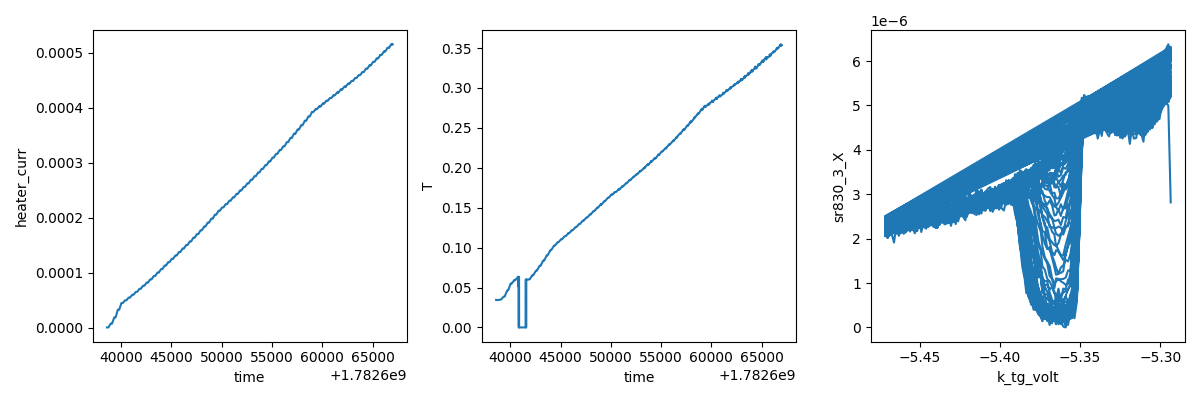

2026-06-28 10:16:18,743 [INFO] Completed in 7h 53m 7s
2026-06-28 10:16:18,745 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\10\data.tsv.gz
2026-06-28 10:16:25,586 [INFO] Ramping k_tg_volt: -5.4715 -> -5.36477247080011
2026-06-28 10:16:25,784 [INFO] Ramping k_bg_volt: 3.8965 -> 3.986915985197646
done; heater 0.00 V, T=354.0 mK, B=0.357 mT


In [29]:
# === Figure 4 (+0.75 mT) — R(T,n) at B = B_eff0 + 0.75 mT, D=-0.64 (intermediate field) ===
# Same 1-tau settled ascending method. Field controller +0.384 mT (= B_eff0+0.75 mT),
# positioned by decreasing |B| from the prior field (one-sided toward 0, no zero-cross).
# CHANGE (operator): add a 1-hour base dwell for full thermalization before the ladder.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
B_TARGET = B_EFF0 + 0.75e-3        # = +0.384 mT (true field +0.75 mT)
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
n_line=np.round(np.arange(-4.0,-6.501,-0.02),3); vt_line,vb_line=nD_to_V(n_line*1e11,-0.64)
assert (vt_line>=-7).all() and (vt_line<=6).all() and (vb_line>=-4).all() and (vb_line<=4.2).all()
vt_opt,vb_opt=[float(x) for x in nD_to_V(-5.0e11,-0.64)]

Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
dc205_1.volt(0.0); sr830_1.amplitude(0.1); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4)
I_bias=0.1/1e8
def Ropt(): return (sr830_3.X()/100)/I_bias

# --- position field (one-sided, read back) ---
print(f"B now {magnet.field()*1e3:.4f} mT; ramping to B_eff0+0.75mT = {B_TARGET*1e3:.3f} mT ...")
magnet.field(B_TARGET); interruptable_sleep(20)
B_read=magnet.field(); print(f"magnet at {B_read*1e3:.4f} mT (true field {(B_read-B_EFF0)*1e3:.2f} mT)")
assert abs(B_read-B_TARGET)<0.2e-3, f"field off target: {B_read*1e3:.3f} mT"

# --- wait for base, post-ramp R-settle, THEN a 1-hour base dwell (more thermalization) ---
print("waiting for base (T<45 mK)...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<60*60: interruptable_sleep(30)
print(f"T={temperature()*1e3:.1f} mK; R-settle (sample plateau after field ramp)...")
Rp=Ropt(); tp=time.monotonic(); ok=0
while True:
    interruptable_sleep(30); Rn=Ropt(); tn=time.monotonic(); dRdt=(Rn-Rp)/((tn-tp)/60); Rp,tp=Rn,tn
    ok = ok+1 if abs(dRdt)<0.4 else 0
    if ok>=2 or tn-t0>15*60: print(f"  R settled: {Ropt():.2f} ohm (dR/dt={dRdt:+.2f}/min)"); break
print("1-hour base dwell for full thermalization (operator request)...")
interruptable_sleep(30*60)
print(f"base dwell done: T={temperature()*1e3:.1f} mK, R(opt)={Ropt():.2f} ohm")

# --- ladder: cap 350 mK, ~80 pts (near-full SC at 0.75 mT, Tc ~190 mK) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(34.0,350.0,80); V_ladder=np.interp(T_targets,T_cal,Vh_cal); DWELL=210
print(f"ladder {len(V_ladder)} steps (34->350 mK, ~{T_targets[1]-T_targets[0]:.1f} mK), slow_delay {DWELL}s (~1 tau); B held {B_read*1e3:.3f} mT")

meas_config["comment"]=(f"Fig4-075 R(T,n); D=-0.64; B={B_read*1e3:.3f} mT (B_eff0+0.75mT, true {(B_read-B_EFF0)*1e3:.2f} mT); "
                        f"ascending {len(V_ladder)}-step 34->350 mK; slow_delay {DWELL}s (~1 tau); n {len(n_line)} pts; "
                        f"AC 1 nA; 4T 0.1 mV; B_eff0={B_EFF0*1e3:.3f} mT; R-settled + 1h base dwell")
s=sweep.AsyncStation(meas_config)
s.add_comment('temperature-dependence'); s.add_comment('Figure 4 (+0.75 mT): R(T,n) at B_eff0+0.75mT, D=-0.64; 1-tau settled, R-settled + 1h base dwell')
s.add_comment(meas_config["comment"])
s.fp(k_tg.volt).fp(k_tg.curr); s.fp(k_bg.volt).fp(k_bg.curr)
s.fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr); s.plot('time', temperature); s.plot(k_tg.volt, sr830_3.X)
try:
    s.multimegasweep([heater.volt],[V_ladder],[k_tg.volt,k_bg.volt],[vt_line,vb_line],
                     slow_delay=DWELL, fast_delay=1, init_delay=False)
finally:
    heater.volt(0.0); s.ramp(k_tg.volt,vt_opt); s.ramp(k_bg.volt,vb_opt)
print(f"done; heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.3f} mT")


## HERA — Fig 5 verify: cheap 1D dV/dI vs I_dc at base (Ic check before the 2D)

Fig 4 done (ξ ≈ 0.30 μm). **Fig 5 = dV/dI vs (I_dc, T)** at the optimum, B=B_eff0 — the brief gates it on a cheap base dV/dI confirming the supercurrent is clean first. **This is that verify.**

Ramps the field **back to B_eff0** (from the +0.75 mT Fig-4 field — a positioning ramp that crosses controller 0; read back), waits for base + R-settle, then a **round-trip dV/dI vs I_dc, ±80 nA** (±8 V on dc205, I_dc=V_dc/1e8). **AC 0.5 nA**, 4T sens 0.1 mV. Round-trip (fwd+bwd) doubles as a hysteresis check. Expect: dV/dI≈0 for |I_dc|<Ic, switching to normal (~50 Ω) at **Ic≈28 nA** with peaks near **±36 nA** (matching run 9 / the handoff).

~5 min (302 pts × ~1 s). Preconditions asserted (gates at optimum, heater off, field on B_eff0). dc205 returns to 0 at the end. **Proceed to the 2D only if this is clean.** If Ic≈28 nA and symmetric, I’ll propose Fig 5 (dV/dI vs I_dc × the settled T-ladder). Run when ready.


In [30]:
# === Fig 5 verify (cheap) — 1D dV/dI vs I_dc at base, optimum, B=B_eff0 ===
# Confirms the supercurrent is clean (Ic ~28 nA, switching ~+/-36 nA) before the
# 2D dV/dI(I_dc, T). Ramps field back to B_eff0 from the Fig-4 field. AC 0.5 nA.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
vt_opt,vb_opt=[float(x) for x in nD_to_V(-5.0e11,-0.64)]

# --- preconditions: gates at optimum, heater off ---
Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
print(f"V_tg={Vtg:.3f} V_bg={Vbg:.3f} heater={Hv:.3f} V; B now {magnet.field()*1e3:.4f} mT")
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"

# --- ramp field back to B_eff0 (from the +0.75 mT Fig-4 field; crosses controller 0) ---
print(f"ramping magnet to B_eff0 = {B_EFF0*1e3:.3f} mT ...")
magnet.field(B_EFF0); interruptable_sleep(20)
B_read=magnet.field(); print(f"magnet at {B_read*1e3:.4f} mT (target B_eff0; true sample field ~0)")
assert abs(B_read-B_EFF0)<0.3e-3, f"field off B_eff0: {B_read*1e3:.3f} mT"

# --- AC 0.5 nA, 4T sens 0.1 mV, zero DC bias to start ---
sr830_1.amplitude(0.05)          # 0.05 V -> 0.5 nA
sr830_2.sensitivity(0.005)
sr830_3.sensitivity(1e-4)        # 0.1 mV (resolves dV/dI 0..2 kOhm at 0.5 nA)
dc205_1.volt(0.0)
I_bias_ac = 0.05/1e8             # 0.5 nA

# --- wait for base + R-settle (field ramp deposited some heat) ---
print("waiting for base (T<45 mK) + R-settle...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<30*60: interruptable_sleep(30)
def Ropt(): return (sr830_3.X()/100)/I_bias_ac
Rp=Ropt(); tp=time.monotonic(); ok=0
while True:
    interruptable_sleep(30); Rn=Ropt(); tn=time.monotonic(); dRdt=(Rn-Rp)/((tn-tp)/60); Rp,tp=Rn,tn
    ok = ok+1 if abs(dRdt)<0.4 else 0
    if ok>=2 or tn-t0>15*60: break
print(f"base: T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.4f} mT, zero-bias dV/dI={Ropt():.2f} ohm")

# --- bias sweep: round-trip +/-80 nA = +/-8 V (I_dc = V_dc/1e8) ---
Vdc=np.hstack((np.linspace(-8,8,151), np.linspace(8,-8,151)))   # round-trip, hysteresis check
print(f"dV/dI vs I_dc round-trip +/-80 nA ({len(Vdc)} pts, delay 1) at base, B_eff0, optimum")
meas_config["comment"]=(f"Fig5-verify 1D dV/dI vs I_dc at base; optimum n=-5.0,D=-0.64; B=B_eff0={B_read*1e3:.3f} mT; "
                        f"round-trip +/-80 nA ({len(Vdc)} pts); AC 0.5 nA; 4T 0.1 mV; confirm Ic before 2D")
s=sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy'); s.add_comment('Fig 5 verify: 1D dV/dI(I_dc) at base, B_eff0, optimum (Ic check)')
s.add_comment(meas_config["comment"])
xp=dc205_1.volt
s.fp(k_tg.volt).fp(k_bg.volt).fp(temperature).fp(magnet.field).fp(dc205_1.volt)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot(xp, sr830_3.X)    # dV/dI vs bias -- the supercurrent dip + switching
s.plot(xp, sr830_1.X)    # AC current monitor
try:
    s.sweep(dc205_1.volt, Vdc, delay=1)
finally:
    dc205_1.volt(0.0)
print(f"done; dc205=0, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.4f} mT")


V_tg=-5.365 V_bg=3.987 heater=0.000 V; B now 0.4085 mT
ramping magnet to B_eff0 = -0.366 mT ...


Sleeping:   0%|          | 0.0/20.0s []

magnet at -0.3703 mT (target B_eff0; true sample field ~0)
waiting for base (T<45 mK) + R-settle...


Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

...

Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

Sleeping:   0%|          | 0.0/30.0s []

KeyboardInterrupt: 

V_tg=-5.365 V_bg=3.987 heater=0.000 V; B now -0.3992 mT
ramping magnet to B_eff0 = -0.366 mT ...


Sleeping:   0%|          | 0.0/20.0s []

magnet at -0.4036 mT (target B_eff0; true sample field ~0)
waiting for base (T<45 mK) + R-settle...
base: T=33.6 mK, B=-0.3839 mT, zero-bias dV/dI=0.30 ohm
dV/dI vs I_dc round-trip +/-80 nA (302 pts, delay 1) at base, B_eff0, optimum
2026-06-28 11:35:03,221 [INFO] Starting sweep with ID 11
2026-06-28 11:35:03,222 [INFO] Minimum duration 0h 5m 2s


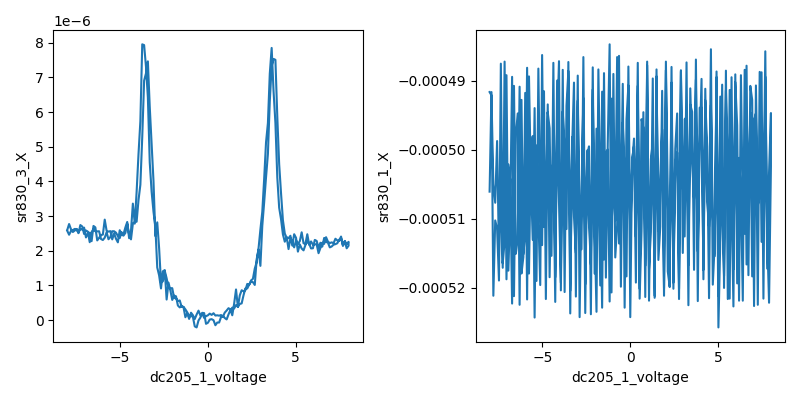

2026-06-28 11:40:42,592 [INFO] Completed in 0h 5m 38s
2026-06-28 11:40:42,594 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\11\data.tsv.gz
done; dc205=0, T=33.6 mK, B=-0.3811 mT


In [31]:
# === Fig 5 verify (cheap) — 1D dV/dI vs I_dc at base, optimum, B=B_eff0 ===
# Confirms the supercurrent is clean (Ic ~28 nA, switching ~+/-36 nA) before the
# 2D dV/dI(I_dc, T). Ramps field back to B_eff0 from the Fig-4 field. AC 0.5 nA.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
vt_opt,vb_opt=[float(x) for x in nD_to_V(-5.0e11,-0.64)]

# --- preconditions: gates at optimum, heater off ---
Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt()
print(f"V_tg={Vtg:.3f} V_bg={Vbg:.3f} heater={Hv:.3f} V; B now {magnet.field()*1e3:.4f} mT")
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"

# --- ramp field back to B_eff0 (from the +0.75 mT Fig-4 field; crosses controller 0) ---
print(f"ramping magnet to B_eff0 = {B_EFF0*1e3:.3f} mT ...")
magnet.field(B_EFF0); interruptable_sleep(20)
B_read=magnet.field(); print(f"magnet at {B_read*1e3:.4f} mT (target B_eff0; true sample field ~0)")
assert abs(B_read-B_EFF0)<0.3e-3, f"field off B_eff0: {B_read*1e3:.3f} mT"

# --- AC 0.5 nA, 4T sens 0.1 mV, zero DC bias to start ---
sr830_1.amplitude(0.05)          # 0.05 V -> 0.5 nA
sr830_2.sensitivity(0.005)
sr830_3.sensitivity(1e-4)        # 0.1 mV (resolves dV/dI 0..2 kOhm at 0.5 nA)
dc205_1.volt(0.0)
I_bias_ac = 0.05/1e8             # 0.5 nA

# --- wait for base + R-settle (field ramp deposited some heat) ---
print("waiting for base (T<45 mK) + R-settle...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<30*60: interruptable_sleep(30)
def Ropt(): return (sr830_3.X()/100)/I_bias_ac
Rp=Ropt(); tp=time.monotonic(); ok=0

print(f"base: T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.4f} mT, zero-bias dV/dI={Ropt():.2f} ohm")

# --- bias sweep: round-trip +/-80 nA = +/-8 V (I_dc = V_dc/1e8) ---
Vdc=np.hstack((np.linspace(-8,8,151), np.linspace(8,-8,151)))   # round-trip, hysteresis check
print(f"dV/dI vs I_dc round-trip +/-80 nA ({len(Vdc)} pts, delay 1) at base, B_eff0, optimum")
meas_config["comment"]=(f"Fig5-verify 1D dV/dI vs I_dc at base; optimum n=-5.0,D=-0.64; B=B_eff0={B_read*1e3:.3f} mT; "
                        f"round-trip +/-80 nA ({len(Vdc)} pts); AC 0.5 nA; 4T 0.1 mV; confirm Ic before 2D")
s=sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy'); s.add_comment('Fig 5 verify: 1D dV/dI(I_dc) at base, B_eff0, optimum (Ic check)')
s.add_comment(meas_config["comment"])
xp=dc205_1.volt
s.fp(k_tg.volt).fp(k_bg.volt).fp(temperature).fp(magnet.field).fp(dc205_1.volt)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot(xp, sr830_3.X)    # dV/dI vs bias -- the supercurrent dip + switching
s.plot(xp, sr830_1.X)    # AC current monitor
try:
    s.sweep(dc205_1.volt, Vdc, delay=1)
finally:
    dc205_1.volt(0.0)
print(f"done; dc205=0, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.4f} mT")


## HERA — Figure 5: dV/dI vs (I_dc, T) at the optimum, B=B_eff0

Verify passed (run 11): clean supercurrent, **Ic≈36 nA** switching, non-hysteretic, symmetric, field at B_eff0. Now the 2D — the supercurrent vs temperature.

**Shape:** heater the **1τ-settled slow axis** (same method as Fig 3: 80 steps, 34→350 mK cap — Ic→0 by Tc≈235 mK, so 350 mK is ample), DC bias the **fast axis** (±80 nA = ±8 V, 161 pts ~1 nA, one-way — verify showed non-hysteretic so no round-trip needed). Optimum n=−5.0, D=−0.64; AC 0.5 nA; 4T 0.1 mV. Field already at B_eff0 (held). Includes the **1-hour base dwell** + R-settle before the ladder (your thermalization standard).

Gives **Ic(T)** — the switching peaks marching inward to 0 as T→Tc, i.e. the supercurrent dome in the (I_dc, T) plane (the arXiv 2504.06972 Fig-5 move). **~9.2 h** (1 h dwell + 80 × (210 s + ~161 s)). Preconditions asserted (gates at optimum, heater off, B=B_eff0 — if B drifted off, it tells you to re-run the verify). dc205 + heater return to 0 at the end. Checkpoints: first steps, then ~hourly. Watch the fridge MC. Run when ready.


V_tg=-5.365 V_bg=3.987 heater=0.000 V; B=-0.4089 mT (expect B_eff0 -0.366)
base wait + R-settle...


Sleeping:   0%|          | 0.0/1200.0s []

base: T=33.6 mK, zero-bias dV/dI=-1.94 ohm
heater 80 steps (34->350 mK, slow_delay 210s ~1 tau); bias 161 pts +/-80 nA
2026-06-28 12:12:50,764 [INFO] Starting multimegasweep with ID 12
2026-06-28 12:12:50,765 [INFO] Minimum duration 8h 14m 40s


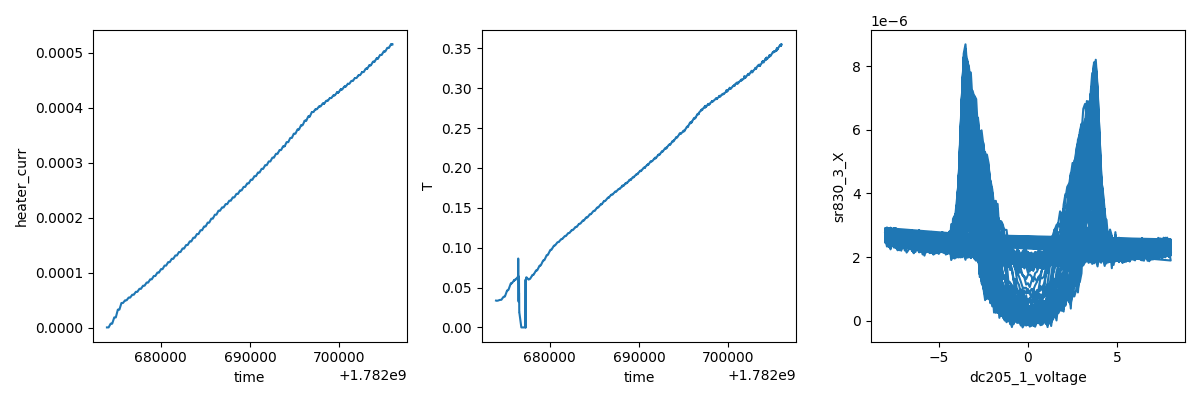

2026-06-28 21:05:51,317 [INFO] Completed in 8h 52m 59s
2026-06-28 21:05:51,317 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\12\data.tsv.gz
done; dc205=0, heater 0.00 V, T=343.0 mK, B=-0.3972 mT


In [33]:
# === Figure 5 — dV/dI vs (I_dc, T) at the optimum, B=B_eff0 ===
# 2D supercurrent-vs-temperature map: heater the 1-tau-settled slow axis, DC bias
# the fast axis. Shows Ic(T) collapsing to 0 at Tc. Verify (run 11) confirmed a
# clean Ic~36 nA at base. Field already at B_eff0 (from the verify).
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
vt_opt,vb_opt=[float(x) for x in nD_to_V(-5.0e11,-0.64)]

# --- preconditions: gates at optimum, heater off, field at B_eff0 ---
Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt(); B_now=magnet.field()
print(f"V_tg={Vtg:.3f} V_bg={Vbg:.3f} heater={Hv:.3f} V; B={B_now*1e3:.4f} mT (expect B_eff0 {B_EFF0*1e3:.3f})")
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
assert abs(B_now-B_EFF0)<0.3e-3, f"B off B_eff0: {B_now*1e3:.3f} mT (re-run the verify to re-zero)"

# --- AC 0.5 nA, 4T sens 0.1 mV, DC bias 0 ---
sr830_1.amplitude(0.05); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4); dc205_1.volt(0.0)
def Ropt(): return (sr830_3.X()/100)/(0.05/1e8)

# --- wait for base + R-settle + 1-hour base dwell (full thermalization) ---
print("base wait + R-settle...")
t0=time.monotonic()
while temperature()>0.045 and time.monotonic()-t0<30*60: interruptable_sleep(30)
Rp=Ropt(); tp=time.monotonic(); ok=0
# while True:
#     interruptable_sleep(30); Rn=Ropt(); tn=time.monotonic(); dRdt=(Rn-Rp)/((tn-tp)/60); Rp,tp=Rn,tn
#     ok = ok+1 if abs(dRdt)<0.4 else 0
#     if ok>=2 or tn-t0>15*60: break
# print("1-hour base dwell for full thermalization...")
interruptable_sleep(20*60)
print(f"base: T={temperature()*1e3:.1f} mK, zero-bias dV/dI={Ropt():.2f} ohm")

# --- axes: heater slow (1-tau, cap 350 mK), DC bias fast (+/-80 nA, one-way) ---
Vh_cal=np.array([0,1,2,3,4,4.5,5,5.5,6,6.5]); T_cal=np.array([34,48.6,100.3,157.7,228.9,262.4,316.6,363.8,428.4,480.3])
T_targets=np.linspace(34.0,350.0,80); V_ladder=np.interp(T_targets,T_cal,Vh_cal); DWELL=210
Vdc=np.linspace(-8.0,8.0,161)                                   # +/-80 nA, ~1 nA step (one-way; verify showed non-hysteretic)
print(f"heater {len(V_ladder)} steps (34->350 mK, slow_delay {DWELL}s ~1 tau); bias {len(Vdc)} pts +/-80 nA")

meas_config["comment"]=(f"Fig5 dV/dI(I_dc,T); optimum n=-5.0,D=-0.64; B=B_eff0={B_now*1e3:.3f} mT; heater slow "
                        f"{len(V_ladder)}-step uniform-T 34->350 mK (~1 tau); bias fast {len(Vdc)} pts +/-80 nA; "
                        f"AC 0.5 nA; 4T 0.1 mV; R-settled + 1h base dwell")
s=sweep.AsyncStation(meas_config)
s.add_comment('bias-spectroscopy'); s.add_comment('Figure 5: dV/dI vs (I_dc, T) at optimum, B_eff0; 1-tau settled heater axis')
s.add_comment(meas_config["comment"])
xp=dc205_1.volt
s.fp(k_tg.volt).fp(k_bg.volt).fp(temperature).fp(fridge_temperature).fp(heater.volt).fp(heater.curr).fp(magnet.field).fp(dc205_1.volt)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot('time', heater.curr); s.plot('time', temperature); s.plot(xp, sr830_3.X)
try:
    s.multimegasweep([heater.volt],[V_ladder],[dc205_1.volt],[Vdc],
                     slow_delay=DWELL, fast_delay=1, init_delay=False)
finally:
    dc205_1.volt(0.0); heater.volt(0.0)
print(f"done; dc205=0, heater {heater.volt():.2f} V, T={temperature()*1e3:.1f} mK, B={magnet.field()*1e3:.4f} mT")


## HERA — Figure 2: Fraunhofer dV/dI(I_dc, B_perp) — the finale (run AFTER the recovery verify)

Fig 5 done (Ic(base)=36 nA, Ic(T)→0 at ~216 mK). **Last figure: the Fraunhofer** — Ic modulation vs perpendicular field, the phase-coherence signature.

**Gate first (recovery verify):** once the fridge is back at base from Fig 5's thermal cycle, **re-run cell 75** (the dV/dI verify). If Ic≈36 nA again, the supercurrent survived cycling — then run this cell. (B_eff0 is reused, NOT re-measured — trapped flux is fixed.)

**This cell:** dV/dI vs (I_dc, B_perp) at the optimum, base T. Field the slow axis — a **single cross-zero pass B_eff0 ± 5 mT** (−5.37→+4.63 mT controller, 0.1 mT step, 101 pts) — the **one authorized cross-zero** (lobe-symmetric scan). Bias the fast axis (±80 nA, 161 pts), AC 0.5 nA, 4T 0.1 mV. The **central lobe (max Ic) should sit at B_eff0**, self-checking the effective zero; side lobes (if present) give ΔB = Φ₀/A → junction area. **~4.6 h.**

Field positioned at the negative extreme then swept up continuously (the sanctioned cross-zero). T watched live for flux-motion heating near 0. Returns to B_eff0 at the end. Per the recipe/brief guardrails I'll claim phase-coherence + Φ₀/area only — NOT a microscopic junction model. Preconditions asserted (optimum, heater off, base T).


In [35]:
interruptable_sleep(30*60)

Sleeping:   0%|          | 0.0/1800.0s []

V_tg=-5.365 V_bg=3.987 heater=0.000 V; T=33.6 mK; B now -0.3548 mT
field 101 steps -5.366->4.634 mT (centered on B_eff0=-0.366); bias 161 pts +/-80 nA
ramping to start -5.366 mT ...


Sleeping:   0%|          | 0.0/30.0s []

at -5.3638 mT; sweeping up through B_eff0 (cross-zero, authorized)
2026-06-28 22:53:22,863 [INFO] Starting multimegasweep with ID 13
2026-06-28 22:53:22,865 [INFO] Minimum duration 4h 36m 4s


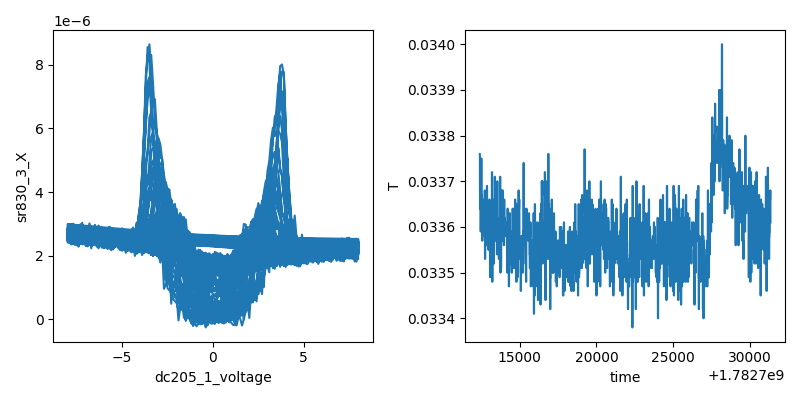

2026-06-29 04:08:57,939 [INFO] Completed in 5h 15m 34s
2026-06-29 04:08:57,940 [INFO] Data saved in C:\Users\toploader\measurements\aaron\20260625-zf1\data\13\data.tsv.gz
done; dc205=0, B=1.3792 mT (B_eff0), T=33.6 mK


In [36]:
# === Figure 2 — Fraunhofer: dV/dI vs (I_dc, B_perp) at the optimum, base T ===
# 2D bias-vs-field map. Single CROSS-ZERO field pass B_eff0 +/- 5 mT (AUTHORIZED,
# the one sanctioned exception to the one-sided rule), 0.1 mT step. Central lobe
# (max Ic) at B_eff0 self-checks the effective zero. Run AFTER the recovery verify.
import scipy.constants as cst, time

B_EFF0 = -0.366e-3
N_OFF=-0.362e11*1e4
cal_r4=GateCalibration.from_thicknesses(t_tg,t_bg,t_bgSiO2,n_offset=N_OFF)
c_tg,c_bg=cal_r4.c_tg,cal_r4.c_bg; e,eps0=cst.e,cst.epsilon_0
def nD_to_V(n_cm2,D):
    n=np.asarray(n_cm2)*1e4; D=np.asarray(D)*1e9
    A=(n-cal_r4.n_offset)*e; B=(D-cal_r4.D_offset)*2*eps0
    return (A+B)/(2*c_tg),(A-B)/(2*c_bg)
vt_opt,vb_opt=[float(x) for x in nD_to_V(-5.0e11,-0.64)]

# --- preconditions: gates at optimum, heater off, base T ---
Vtg=k_tg.volt(); Vbg=k_bg.volt(); Hv=heater.volt(); T0=temperature()
print(f"V_tg={Vtg:.3f} V_bg={Vbg:.3f} heater={Hv:.3f} V; T={T0*1e3:.1f} mK; B now {magnet.field()*1e3:.4f} mT")
assert abs(Vtg-(-5.365))<0.010 and abs(Vbg-(+3.987))<0.010, "gates off optimum"
assert Hv<0.01, "heater not off"
assert T0<0.060, f"not at base: {T0*1e3:.1f} mK"

sr830_1.amplitude(0.05); sr830_2.sensitivity(0.005); sr830_3.sensitivity(1e-4); dc205_1.volt(0.0)

# --- field axis: single cross-zero pass B_eff0 +/- 5 mT (authorized); bias fast +/-80 nA ---
B_vec=np.round(np.arange(B_EFF0-5e-3, B_EFF0+5e-3+0.05e-3, 0.1e-3), 6)   # ~101 steps, low->high (one cross-zero)
Vdc=np.linspace(-8.0,8.0,161)                                            # +/-80 nA
print(f"field {len(B_vec)} steps {B_vec[0]*1e3:.3f}->{B_vec[-1]*1e3:.3f} mT (centered on B_eff0={B_EFF0*1e3:.3f}); bias {len(Vdc)} pts +/-80 nA")
assert abs(B_vec).max() < 0.1, "field exceeds session cap"

# position at the negative extreme, settle (single continuous pass from here)
print(f"ramping to start {B_vec[0]*1e3:.3f} mT ...")
magnet.field(float(B_vec[0])); interruptable_sleep(30)
print(f"at {magnet.field()*1e3:.4f} mT; sweeping up through B_eff0 (cross-zero, authorized)")

meas_config["comment"]=(f"Fig2 Fraunhofer dV/dI(I_dc,B_perp); optimum n=-5.0,D=-0.64; base T; B_eff0={B_EFF0*1e3:.3f} mT; "
                        f"field slow {len(B_vec)} pts {B_vec[0]*1e3:.2f}->{B_vec[-1]*1e3:.2f} mT (cross-zero, 0.1 mT); "
                        f"bias fast {len(Vdc)} pts +/-80 nA; AC 0.5 nA; 4T 0.1 mV")
s=sweep.AsyncStation(meas_config)
s.add_comment('fraunhofer'); s.add_comment('Figure 2: Fraunhofer dV/dI(I_dc, B_perp) at optimum, base T; cross-zero centered on B_eff0')
s.add_comment(meas_config["comment"])
xp=dc205_1.volt
s.fp(k_tg.volt).fp(k_bg.volt).fp(temperature).fp(magnet.field).fp(dc205_1.volt)
for lia in (sr830_1,sr830_2,sr830_3): s.fp(lia.X).fp(lia.P)
s.plot(xp, sr830_3.X)            # dV/dI vs bias at each field
s.plot('time', temperature)      # watch for ramp/flux heating near 0
try:
    s.multimegasweep([magnet.field],[B_vec],[dc205_1.volt],[Vdc],
                     slow_delay=3, fast_delay=1, init_delay=False)
finally:
    dc205_1.volt(0.0); magnet.field(B_EFF0)   # return to B_eff0
print(f"done; dc205=0, B={magnet.field()*1e3:.4f} mT (B_eff0), T={temperature()*1e3:.1f} mK")


In [37]:
k_tg.volt(0)
k_bg.volt(0)